In [ ]:
from google.colab import drive

print("Connecting to your Google Drive...")
drive.mount('/content/drive')

Connecting to your Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

# Define the exact destination folder layout inside your Google Drive
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'

print(f"Creating project directories at: {DATASET_DIR}")
os.makedirs(DATASET_DIR, exist_ok=True)
print("✓ Target folders successfully built or already present!")

Creating project directories at: /content/drive/My Drive/FedLungProject/datasets
✓ Target folders successfully built or already present!


In [ ]:
import os

ZIP_FILE_PATH = '/content/drive/My Drive/FedLungProject.zip'
EXTRACT_TARGET_DIR = '/content/drive/My Drive/FedLungProject/datasets'

if os.path.exists(ZIP_FILE_PATH):
    print("Zip archive found! Beginning extraction process... Please wait 1 to 2 minutes.")
    !unzip -q "{ZIP_FILE_PATH}" -d "{EXTRACT_TARGET_DIR}"
    print("✓ Extraction completely finished!")
else:
    print("✗ Error: Unable to locate 'FedLungProject.zip' at the root of your Google Drive.")

Zip archive found! Beginning extraction process... Please wait 1 to 2 minutes.
replace /content/drive/My Drive/FedLungProject/datasets/Chest-X-Ray/Chest-X-Ray/image/1000.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: ✓ Extraction completely finished!


In [ ]:
import os

DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'

print("--- Checking what is inside the datasets folder ---")
if os.path.exists(DATASET_DIR):
    contents = os.listdir(DATASET_DIR)
    print("Found items:", contents)

    # Check if there's a nested folder named 'Chest-X-Ray'
    nested_path = os.path.join(DATASET_DIR, 'Chest-X-Ray')
    if os.path.exists(nested_path):
        print("\nFound nested 'Chest-X-Ray' folder. Inside it:")
        print(os.listdir(nested_path))
else:
    print("Datasets folder does not exist.")

--- Checking what is inside the datasets folder ---
Found items: ['MetaData.csv', 'Chest-X-Ray']

Found nested 'Chest-X-Ray' folder. Inside it:
['Chest-X-Ray']


In [ ]:
import os
import pandas as pd

# Define the absolute root of your dataset folder
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'
csv_path = os.path.join(DATASET_DIR, 'MetaData.csv')

# Update the image and mask folders to use the nested paths
IMAGE_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/image')
MASK_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/mask')

if os.path.exists(csv_path):
    df = pd.read_csv(csv_path)
    print("✅ FILE SYSTEM MAPPING SUCCESS!")
    print(f"Total Rows indexed inside MetaData.csv: {len(df)}")
    print(f"Actual image files found on drive: {len(os.listdir(IMAGE_DIR))}")
    print(f"Actual mask files found on drive: {len(os.listdir(MASK_DIR))}")
else:
    print("✗ Error: Still unable to verify files. Check your spelling.")

✅ FILE SYSTEM MAPPING SUCCESS!
Total Rows indexed inside MetaData.csv: 704
Actual image files found on drive: 704
Actual mask files found on drive: 704


In [ ]:
print("Installing required framework packages... Please wait.")
!pip install -q flwr segmentation-models-pytorch albumentations
print("✓ Framework installations complete and ready for use!")

Installing required framework packages... Please wait.
✓ Framework installations complete and ready for use!


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Set runtime device to leverage the Colab T4 GPU
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Hardware Device: {DEVICE}")

# Set paths for the rest of the code blocks
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'
IMAGE_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/image')
MASK_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/mask')

Active Hardware Device: cuda


In [ ]:
import os
import pandas as pd
import cv2
from torch.utils.data import Dataset

class FederatedLungDataset(Dataset):
    def __init__(self, csv_path, img_dir, mask_dir, county_name, transform=None):
        """
        county_name: 'montgomery' or 'shenzhen'
        """
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        self.transform = transform

        # Load the index sheet
        df = pd.read_csv(csv_path)

        # Isolate the data into client-specific subsets
        if county_name.lower() == 'montgomery':
            self.filtered_df = df[df['county'].str.lower() == 'montgomery'].reset_index(drop=True)
        elif county_name.lower() == 'shenzhen':
            self.filtered_df = df[df['county'].str.lower().str.contains('shen')].reset_index(drop=True)
        else:
            raise ValueError("Unknown client node name. Select 'montgomery' or 'shenzhen'.")

    def __len__(self):
        return len(self.filtered_df)

    def __getitem__(self, idx):
        # Extract file identifier and force it to be a clean string
        raw_id = self.filtered_df.iloc[idx]['id']
        img_name = str(raw_id)

        # If the index misses the extension, append it automatically
        if not img_name.endswith('.png'):
            img_name = img_name + '.png'

        img_path = os.path.join(self.img_dir, img_name)
        mask_path = os.path.join(self.mask_dir, img_name)

        # Read files using OpenCV
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Could not find image at: {img_path}")

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) # Force to standard RGB format
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) # Masks are 1-channel arrays
        if mask is None:
            raise FileNotFoundError(f"Could not find mask at: {mask_path}")

        # Apply transformation matrices simultaneously
        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        # Convert mask pixels to a binary float (0.0 or 1.0) and add channel dimension
        mask = (mask > 0).float().unsqueeze(0)

        return image, mask

In [ ]:
from torch.utils.data import random_split

# 1. Define configurations for your training transformations
train_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# Re-verify absolute paths established earlier
DATASET_DIR = '/content/drive/My Drive/FedLungProject/datasets'
CSV_PATH = os.path.join(DATASET_DIR, 'MetaData.csv')
IMAGE_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/image')
MASK_DIR = os.path.join(DATASET_DIR, 'Chest-X-Ray/Chest-X-Ray/mask')

# 2. Build full institutional datasets
full_client0_dataset = FederatedLungDataset(CSV_PATH, IMAGE_DIR, MASK_DIR, 'montgomery', transform=train_transforms)
full_client1_dataset = FederatedLungDataset(CSV_PATH, IMAGE_DIR, MASK_DIR, 'shenzhen', transform=train_transforms)

# 3. Create rigorous 80/20 train/validation splits per client node
c0_train_len = int(len(full_client0_dataset) * 0.8)
c0_val_len = len(full_client0_dataset) - c0_train_len
client0_train_set, client0_val_set = random_split(full_client0_dataset, [c0_train_len, c0_val_len], generator=torch.Generator().manual_seed(42))

c1_train_len = int(len(full_client1_dataset) * 0.8)
c1_val_len = len(full_client1_dataset) - c1_train_len
client1_train_set, client1_val_set = random_split(full_client1_dataset, [c1_train_len, c1_val_len], generator=torch.Generator().manual_seed(42))

# 4. Initialize isolated DataLoaders
client0_train_loader = DataLoader(client0_train_set, batch_size=8, shuffle=True)
client0_val_loader = DataLoader(client0_val_set, batch_size=8, shuffle=False)

client1_train_loader = DataLoader(client1_train_set, batch_size=8, shuffle=True)
client1_val_loader = DataLoader(client1_val_set, batch_size=8, shuffle=False)

print("--- Data Split Audit Complete ---")
print(f"✓ Client 0 (Montgomery) -> Train Patches: {len(client0_train_set)}, Val Patches: {len(client0_val_set)}")
print(f"✓ Client 1 (Shenzhen)   -> Train Patches: {len(client1_train_set)}, Val Patches: {len(client1_val_set)}")

--- Data Split Audit Complete ---
✓ Client 0 (Montgomery) -> Train Patches: 110, Val Patches: 28
✓ Client 1 (Shenzhen)   -> Train Patches: 452, Val Patches: 114


--- Tensor Boundary Verifications ---
Images Shape: torch.Size([8, 3, 224, 224]) (Expected: [8, 3, 224, 224])
Masks Shape:  torch.Size([8, 1, 224, 224]) (Expected: [8, 1, 224, 224])



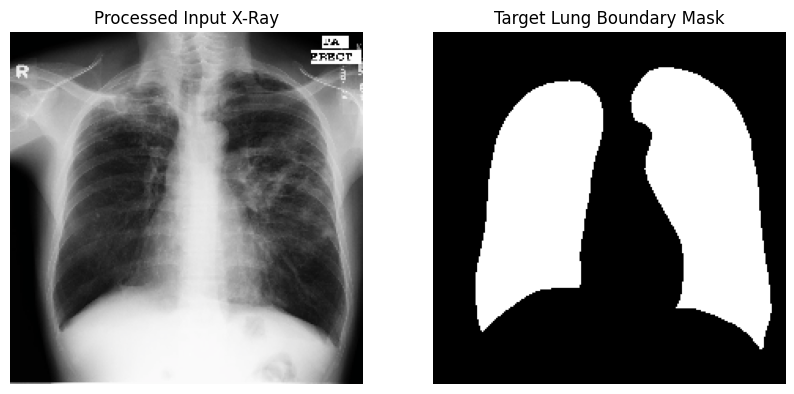

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Grab a sample test batch from Client 0's active data stream
test_images, test_masks = next(iter(client0_train_loader))

print("--- Tensor Boundary Verifications ---")
print(f"Images Shape: {test_images.shape} (Expected: [8, 3, 224, 224])")
print(f"Masks Shape:  {test_masks.shape} (Expected: [8, 1, 224, 224])\n")

# 2. Reverse normalize the sample image to display it in standard RGB colorspace
sample_img = test_images[0].permute(1, 2, 0).cpu().numpy()
sample_img = (sample_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
sample_img = np.clip(sample_img, 0, 1)

# 3. Pull out the matching single-channel segmentation target mask
sample_mask = test_masks[0].squeeze().cpu().numpy()

# 4. Render the plot
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(sample_img)
ax[0].set_title("Processed Input X-Ray")
ax[0].axis('off')

ax[1].imshow(sample_mask, cmap='gray')
ax[1].set_title("Target Lung Boundary Mask")
ax[1].axis('off')

plt.show()

In [ ]:
#10

import torch
import torch.nn as nn
import torchvision.models as models
import torch.nn.functional as F

class TransformerBottleneck(nn.Module):
    """
    Vision Transformer bottleneck layer designed to capture long-range global contexts
    and explicitly extract inner self-attention maps for XAI validation checks.
    """
    def __init__(self, in_channels, dim=512, num_heads=8, depth=1):
        super().__init__()
        self.dim = dim
        self.num_heads = num_heads

        # Project spatial grids to transformer token dimensions
        self.proj = nn.Conv2d(in_channels, dim, kernel_size=1)

        # Multi-Head Attention layers
        self.attn_layers = nn.ModuleList([
            nn.MultiheadAttention(embed_dim=dim, num_heads=num_heads, batch_first=True)
            for _ in range(depth)
        ])
        self.ln = nn.LayerNorm(dim)
        self.unproj = nn.Conv2d(dim, in_channels, kernel_size=1)

        # Target placeholder to store captured XAI attention arrays
        self.extracted_attention_maps = None

    def forward(self, x):
        B, C, H, W = x.shape
        feat = self.proj(x) # Shape: [B, dim, H, W]
        feat = feat.flatten(2).permute(0, 2, 1) # Reshape to sequence tokens: [B, H*W, dim]

        out = feat
        for attn in self.attn_layers:
            # Extract and store attention weights matrix (Q x K^T) during runtime
            attn_out, attn_weights = attn(
    self.ln(out),
    self.ln(out),
    self.ln(out),
    need_weights=True,
    average_attn_weights=False
)
            out = out + attn_out
            self.extracted_attention_maps = attn_weights # Matrix size: [B, H*W, H*W]

        out = out.permute(0, 2, 1).reshape(B, self.dim, H, W)
        return self.unproj(out)

class TransUNetMini(nn.Module):
    """
    Hybrid CNN-Transformer network architecture that integrates a pre-trained ResNet
    encoder backbone with a Vision Transformer bottleneck and a convolutional decoder.
    """
    def __init__(self):
        super().__init__()
        # 1. Base Encoder Architecture
        base_resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.init_conv = nn.Sequential(base_resnet.conv1, base_resnet.bn1, base_resnet.relu, base_resnet.maxpool)

        # Skip Connection Layers
        self.layer1 = base_resnet.layer1 # Output: 64 channels
        self.layer2 = base_resnet.layer2 # Output: 128 channels
        self.layer3 = base_resnet.layer3 # Output: 256 channels
        self.layer4 = base_resnet.layer4 # Output: 512 channels

        # 2. Vision Transformer Core Bottleneck
        self.vit_bottleneck = TransformerBottleneck(in_channels=512, dim=512, num_heads=8)

        # 3. Convolutional Decoder Network
        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec_conv1 = nn.Sequential(nn.Conv2d(512, 256, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec_conv2 = nn.Sequential(nn.Conv2d(256, 128, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec_conv3 = nn.Sequential(nn.Conv2d(128, 64, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        self.up4 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec_conv4 = nn.Sequential(nn.Conv2d(32, 32, kernel_size=3, padding=1), nn.ReLU(inplace=True))

        # Final Segmentation Output Projection Map
        self.final_mask_projection = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        # Encoder Pass with Skip Connection Registrations
        x0 = self.init_conv(x)      # Shape: [B, 64, 56, 56]
        x1 = self.layer1(x0)        # Shape: [B, 64, 56, 56]
        x2 = self.layer2(x1)        # Shape: [B, 128, 28, 28]
        x3 = self.layer3(x2)        # Shape: [B, 256, 14, 14]
        x4 = self.layer4(x3)        # Shape: [B, 512, 7, 7]

        # Transformer Bottleneck Pass
        b_out = self.vit_bottleneck(x4) # Shape: [B, 512, 7, 7]

        # Decoder Pass with Skip Connection Merges
        d1 = self.up1(b_out)
        d1 = torch.cat([d1, x3], dim=1) # Target Grid Size: 14x14
        d1 = self.dec_conv1(d1)

        d2 = self.up2(d1)
        d2 = torch.cat([d2, x2], dim=1) # Target Grid Size: 28x28
        d2 = self.dec_conv2(d2)

        d3 = self.up3(d2)
        d3 = torch.cat([d3, x1], dim=1) # Target Grid Size: 56x56
        d3 = self.dec_conv3(d3)

        d4 = self.up4(d3) # Upsamples to 112x112 spatial footprint
        d4 = self.dec_conv4(d4)

        # Upsample directly to match original input size (224x224)
        d5 = F.interpolate(d4, scale_factor=2, mode='bilinear', align_corners=True)

        return self.final_mask_projection(d5)

# Initialize and assign the model to your hardware accelerator
MODEL = TransUNetMini().to(DEVICE)

# 4. Standard Medical Cost Evaluation Functions
import segmentation_models_pytorch as smp
dice_loss = smp.losses.DiceLoss(mode='binary')
bce_loss = nn.BCEWithLogitsLoss()

def compute_loss(predictions, targets):
    return bce_loss(predictions, targets) + dice_loss(predictions, targets)

def compute_dice_coefficient(preds, targets, threshold=0.5):
    preds = (torch.sigmoid(preds) > threshold).float()
    intersection = (preds * targets).sum()
    total = preds.sum() + targets.sum()
    if total == 0:
        return 1.0
    return (2. * intersection) / total

print("✓ Custom TransUNet compiled successfully with embedded XAI hooks.")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 145MB/s]


✓ Custom TransUNet compiled successfully with embedded XAI hooks.


In [ ]:
def train_local_epoch(model, dataloader, optimizer, device):
    model.train()
    running_loss = 0.0
    running_dice = 0.0

    for images, masks in dataloader:
        images = images.to(device)
        masks = masks.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)
        loss = compute_loss(outputs, masks)

        # Backward pass & weight optimization
        loss.backward()
        optimizer.step()

        # Track statistics
        running_loss += loss.item() * images.size(0)
        running_dice += compute_dice_coefficient(outputs, masks).item() * images.size(0)

    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_dice = running_dice / len(dataloader.dataset)
    return epoch_loss, epoch_dice

In [ ]:
# Pull a sample validation batch from our new validation loader stream
sample_imgs, sample_msks = next(iter(client0_val_loader)) # <-- UPDATED VARIABLE NAME
sample_imgs = sample_imgs.to(DEVICE)

# Turn off gradient calculations for a simple forward pass
with torch.no_grad():
    MODEL.eval()
    test_outputs = MODEL(sample_imgs)

print("--- Architecture Output Check ---")
print(f"Input batch tensor shape:  {sample_imgs.shape}")
print(f"Model output logit shape:  {test_outputs.shape} (Expected: [8, 1, 224, 224])")
print("\n✅ MODEL ARCHITECTURE PASSED DIMENSIONAL SANITY CHECK!")

--- Architecture Output Check ---
Input batch tensor shape:  torch.Size([8, 3, 224, 224])
Model output logit shape:  torch.Size([8, 1, 224, 224]) (Expected: [8, 1, 224, 224])

✅ MODEL ARCHITECTURE PASSED DIMENSIONAL SANITY CHECK!


In [ ]:
print("Installing Flower simulation dependencies and Ray backend...")
!pip install -q -U "flwr[simulation]"
print("✓ Simulation patch successfully installed!")

Installing Flower simulation dependencies and Ray backend...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 11.3 MB/s eta 0:00:00
✓ Simulation patch successfully installed!


In [ ]:
##14

import flwr as fl
import torch
import torch.nn as nn
import torch.optim as optim
import collections

class FlowerClient(fl.client.NumPyClient):
    def __init__(self, model, trainloader, valloader, device):
        self.model = model
        self.trainloader = trainloader
        self.valloader = valloader
        self.device = device
        self.optimizer = optim.Adam(self.model.parameters(), lr=1e-4)

    def get_parameters(self, config):
        return [val.cpu().numpy() for _, val in self.model.state_dict().items()]

    def set_parameters(self, parameters):
        params_dict = zip(self.model.state_dict().keys(), parameters)
        state_dict = collections.OrderedDict({k: torch.tensor(v) for k, v in params_dict})
        self.model.load_state_dict(state_dict, strict=True)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        # Train on the isolated training subset
        loss, dice = train_local_epoch(self.model, self.trainloader, self.optimizer, self.device)
        return self.get_parameters(config={}), len(self.trainloader.dataset), {"loss": loss, "dice": dice}

    def evaluate(self, parameters, config):
        self.set_parameters(parameters)
        self.model.eval()
        running_loss = 0.0
        running_dice = 0.0

        # Evaluate performance using the unseen validation subset
        with torch.no_grad():
            for images, masks in self.valloader:
                images = images.to(self.device)
                masks = masks.to(self.device)
                outputs = self.model(images)
                loss = compute_loss(outputs, masks)

                running_loss += loss.item() * images.size(0)
                running_dice += compute_dice_coefficient(outputs, masks).item() * images.size(0)

        val_loss = running_loss / len(self.valloader.dataset)
        val_dice = running_dice / len(self.valloader.dataset)

        return float(val_loss), len(self.valloader.dataset), {"dice": float(val_dice)}

In [ ]:
def client_fn(cid: str) -> fl.client.Client:
    """
    Dynamically instantiates a client instance with the correct TransUNet architecture.
    """
    # 1. Force the simulation to use the Transformer network
    local_model = TransUNetMini().to(DEVICE)

    # 2. Route data loaders dynamically based on client identifiers
    if cid == "0":
        return FlowerClient(local_model, client0_train_loader, client0_val_loader, DEVICE).to_client()
    elif cid == "1":
        return FlowerClient(local_model, client1_train_loader, client1_val_loader, DEVICE).to_client()
    else:
        raise ValueError(f"Invalid client ID requested: {cid}")

In [ ]:
import flwr as fl
import torch
import collections

# 1. Define the metric aggregator
def aggregate_metrics(metrics):
    total_examples = sum([num_examples for num_examples, _ in metrics])
    weighted_dice = sum([num_examples * m["dice"] for num_examples, m in metrics])
    return {"dice": weighted_dice / total_examples}

# 2. Define a save hook to capture the global trained weights out of the sandbox
def get_evaluate_fn():
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        # Create a temporary model instance to hold the aggregated server weights
        temp_model = TransUNetMini()
        params_dict = zip(temp_model.state_dict().keys(), parameters)
        state_dict = collections.OrderedDict({k: torch.tensor(v) for k, v in params_dict})
        temp_model.load_state_dict(state_dict, strict=True)

        # Save the weights safely to your Google Drive folder
        save_path = f"/content/drive/My Drive/FedLungProject/global_model_round_{server_round}.pth"
        torch.save(temp_model.state_dict(), save_path)
        print(f"💾 Saved global server weights for Round {server_round} to Drive!")

        return 0.0, {} # Return empty evaluation metrics to server
    return evaluate

# 3. Configure strategy with the save hook
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=2,
    min_evaluate_clients=2,
    min_available_clients=2,
    evaluate_metrics_aggregation_fn=aggregate_metrics,
    evaluate_fn=get_evaluate_fn()  # <-- Activates the weight saving hook
)

print("🚀 STARTING SIMULATION...")
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=2,
    config=fl.server.ServerConfig(num_rounds=3),
    strategy=strategy,
    client_resources={"num_gpus": 0.5 if torch.cuda.is_available() else 0, "num_cpus": 1}
)
print("\n🏆 SIMULATION COMPLETED SUCCESSFULLY!")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=3, no round_timeout


🚀 STARTING SIMULATION...


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-07-02 12:55:21,601	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'node:172.28.0.12': 1.0, 'object_store_memory': 3962695680.0, 'accelerator_type:T4': 1.0, 'node:__internal_head__': 1.0, 'memory': 9246289920.0, 'GPU': 1.0, 'CPU': 2.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_gpus': 0.5, 'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(ClientAp

💾 Saved global server weights for Round 0 to Drive!


(ClientAppActor pid=23114) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=23114) 
(ClientAppActor pid=23114)             This is a deprecated feature. It will be removed
(ClientAppActor pid=23114)             entirely in future versions of Flower.
(ClientAppActor pid=23114)         
(ClientAppActor pid=23115) 
(ClientAppActor pid=23115)         
(ClientAppActor pid=23115) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=23115)             This is a deprecated feature. It will be removed
(ClientAppActor pid=23115)             entirely in future versions of Fl

...

(ClientAppActor pid=23114) 
(ClientAppActor pid=23114)         
(ClientAppActor pid=23114) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context` [repeated 2x across cluster]
(ClientAppActor pid=23114)             This is a deprecated feature. It will be removed [repeated 2x across cluster]
(ClientAppActor pid=23114)             entirely in future versions of Flower. [repeated 2x across cluster]
(ClientAppActor pid=23115) 
(ClientAppActor pid=23115)         
INFO :      aggregate_evaluate: received 2 results and 0 failures
INFO :      
INFO :      [ROUND 3]
INFO :      configure_fit: strategy sampled 2 clients (out of 2)
(ClientAppActor pid=23114) 
(ClientAppActor pid=23114)         
(ClientAppActor pid=23114) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(contex

💾 Saved global server weights for Round 3 to Drive!


(ClientAppActor pid=23115) 
(ClientAppActor pid=23115)         
(ClientAppActor pid=23115) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context` [repeated 2x across cluster]
(ClientAppActor pid=23115)             This is a deprecated feature. It will be removed [repeated 2x across cluster]
(ClientAppActor pid=23115)             entirely in future versions of Flower. [repeated 2x across cluster]
(ClientAppActor pid=23114) 
(ClientAppActor pid=23114)         
INFO :      aggregate_evaluate: received 2 results and 0 failures
INFO :      
INFO :      [SUMMARY]
INFO :      Run finished 3 round(s) in 414.83s
INFO :      	History (loss, distributed):
INFO :      		round 1: 0.4687468174477698
INFO :      		round 2: 0.2153296865208048
INFO :      		round 3: 0.1688938753705629
INFO :      	History (loss, ce


🏆 SIMULATION COMPLETED SUCCESSFULLY!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


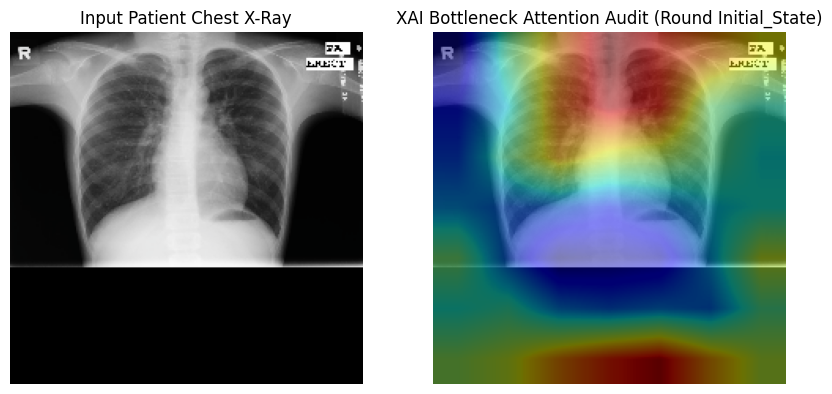

✓ Diagnostic visual proof saved successfully to Drive storage: /content/drive/My Drive/FedLungProject/attention_audit_round_Initial_State.png


In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np

def generate_and_save_attention_heatmap(round_num):
    # 1. Pull a single sample chest X-ray image from your validation loader
    MODEL.eval()
    images, masks = next(iter(client0_val_loader))
    single_img = images[0:1].to(DEVICE) # Isolate single item as batch

    # 2. Run an evaluation forward pass to trigger attention storage hooks
    with torch.no_grad():
        _ = MODEL(single_img)

    # 3. Pull out the captured internal attention matrix weights
    # Shape of map: [1, Num_Heads, Token_Sequence, Token_Sequence] -> [1, 49, 49] for 7x7 spatial resolution
    attn_map = MODEL.vit_bottleneck.extracted_attention_maps[0].cpu().numpy()

    # Average the attention weights across all sequences to find overall regional focus
    mean_attn = np.mean(attn_map, axis=0) # Shape: [49]
    heatmap_grid = mean_attn.reshape(7, 7) # Reconstruct original 7x7 token configuration

    # Resize the heatmap up to 224x224 to match your source image size
    heatmap_resized = cv2.resize(heatmap_grid, (224, 224))
    heatmap_resized = (heatmap_resized - heatmap_resized.min()) / (heatmap_resized.max() - heatmap_resized.min() + 1e-8)

    # 4. Reverse-normalize the source chest X-ray to display it in viewable RGB colorspace
    src_img = single_img[0].permute(1, 2, 0).cpu().numpy()
    src_img = (src_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    src_img = np.clip(src_img, 0, 1)

    # 5. Render and plot the visual validation audit side-by-side
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(src_img)
    ax[0].set_title("Input Patient Chest X-Ray")
    ax[0].axis('off')

    # Overlay the attention heatmap onto the patient chest image
    ax[1].imshow(src_img)
    ax[1].imshow(heatmap_resized, cmap='jet', alpha=0.45) # Blend using jet color spectrum mappings
    ax[1].set_title(f"XAI Bottleneck Attention Audit (Round {round_num})")
    ax[1].axis('off')

    # 6. Save the generated explanation graphic directly to your Google Drive repository
    output_save_path = f"/content/drive/My Drive/FedLungProject/attention_audit_round_{round_num}.png"
    plt.savefig(output_save_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f"✓ Diagnostic visual proof saved successfully to Drive storage: {output_save_path}")

# Run an audit visualization test using the initial global state model
generate_and_save_attention_heatmap(round_num="Initial_State")

📥 Found saved server weights! Loading: /content/drive/My Drive/FedLungProject/global_model_round_3.pth


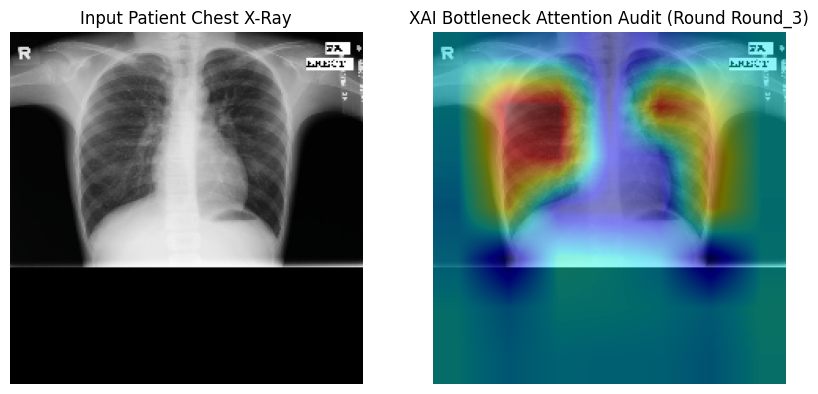

✓ Diagnostic visual proof saved successfully to Drive storage: /content/drive/My Drive/FedLungProject/attention_audit_round_Round_3.png



In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch
import os
import re

def generate_and_save_attention_heatmap(round_num):
    # 1. Look for and load the saved global weights from Google Drive if available
    MODEL.eval()

    # Extract any number from the round_num string (e.g., "Round_3" -> "3")
    round_digits = re.findall(r'\d+', str(round_num))

    if round_digits:
        round_idx = round_digits[0]
        weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{round_idx}.pth"

        if os.path.exists(weight_file):
            print(f"📥 Found saved server weights! Loading: {weight_file}")
            MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
        else:
            print(f"⚠️ Warning: Expected weights file at '{weight_file}' but it wasn't found. Using current model state.")
    else:
        print("ℹ️ Generating baseline heatmap (No round number found, assuming Initial/Untrained state).")

    # 2. Pull a single sample chest X-ray image from your validation loader
    images, masks = next(iter(client0_val_loader))
    single_img = images[0:1].to(DEVICE) # Isolate single item as batch

    # 3. Run an evaluation forward pass to trigger attention storage hooks
    with torch.no_grad():
        _ = MODEL(single_img)

    # 4. Pull out the captured internal attention matrix weights
    attn_map = MODEL.vit_bottleneck.extracted_attention_maps[0].cpu().numpy()

    # Average the attention weights across all sequences to find overall regional focus
    mean_attn = np.mean(attn_map, axis=0) # Shape: [49]
    heatmap_grid = mean_attn.reshape(7, 7) # Reconstruct original 7x7 token configuration

    # Resize the heatmap up to 224x224 to match your source image size
    heatmap_resized = cv2.resize(heatmap_grid, (224, 224))
    heatmap_resized = (heatmap_resized - heatmap_resized.min()) / (heatmap_resized.max() - heatmap_resized.min() + 1e-8)

    # 5. Reverse-normalize the source chest X-ray to display it in viewable RGB colorspace
    src_img = single_img[0].permute(1, 2, 0).cpu().numpy()
    src_img = (src_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    src_img = np.clip(src_img, 0, 1)

    # 6. Render and plot the visual validation audit side-by-side
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(src_img)
    ax[0].set_title("Input Patient Chest X-Ray")
    ax[0].axis('off')

    # Overlay the attention heatmap onto the patient chest image
    ax[1].imshow(src_img)
    ax[1].imshow(heatmap_resized, cmap='jet', alpha=0.45) # Blend using jet color spectrum mappings
    ax[1].set_title(f"XAI Bottleneck Attention Audit (Round {round_num})")
    ax[1].axis('off')

    # 7. Save the generated explanation graphic directly to your Google Drive repository
    output_save_path = f"/content/drive/My Drive/FedLungProject/attention_audit_round_{round_num}.png"
    plt.savefig(output_save_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f"✓ Diagnostic visual proof saved successfully to Drive storage: {output_save_path}\n")

# --- EXECUTION ---
# Run this line to see the trained attention map from the server
generate_and_save_attention_heatmap(round_num="Round_3")

In [ ]:
#16

import flwr as fl
import torch
import collections

# 1. Define the metric aggregator
def aggregate_metrics(metrics):
    total_examples = sum([num_examples for num_examples, _ in metrics])
    weighted_dice = sum([num_examples * m["dice"] for num_examples, m in metrics])
    return {"dice": weighted_dice / total_examples}

# 2. Define a save hook to capture the global trained weights out of the sandbox
def get_evaluate_fn():
    def evaluate(server_round: int, parameters: fl.common.NDArrays, config: dict):
        # Create a temporary model instance to hold the aggregated server weights
        temp_model = TransUNetMini()
        params_dict = zip(temp_model.state_dict().keys(), parameters)
        state_dict = collections.OrderedDict({k: torch.tensor(v) for k, v in params_dict})
        temp_model.load_state_dict(state_dict, strict=True)

        # Save the weights safely to your Google Drive folder
        save_path = f"/content/drive/My Drive/FedLungProject/global_model_round_{server_round}.pth"
        torch.save(temp_model.state_dict(), save_path)
        print(f"💾 Saved global server weights for Round {server_round} to Drive!")

        return 0.0, {} # Return empty evaluation metrics to server
    return evaluate

# 3. Configure strategy with the save hook
strategy = fl.server.strategy.FedAvg(
    fraction_fit=1.0,
    fraction_evaluate=1.0,
    min_fit_clients=2,
    min_evaluate_clients=2,
    min_available_clients=2,
    evaluate_metrics_aggregation_fn=aggregate_metrics,
    evaluate_fn=get_evaluate_fn()  # <-- Activates the weight saving hook
)

print("🚀 STARTING SIMULATION...")
history = fl.simulation.start_simulation(
    client_fn=client_fn,
    num_clients=2,
    config=fl.server.ServerConfig(num_rounds=15),
    strategy=strategy,
    client_resources={"num_gpus": 0.5 if torch.cuda.is_available() else 0, "num_cpus": 1}
)
print("\n🏆 SIMULATION COMPLETED SUCCESSFULLY!")

🚀 STARTING SIMULATION...


	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

💾 Saved global server weights for Round 0 to Drive!


(ClientAppActor pid=5721) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5721) 
(ClientAppActor pid=5721)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5721)             entirely in future versions of Flower.
(ClientAppActor pid=5721)         
(ClientAppActor pid=5722) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5722) 
(ClientAppActor pid=5722)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5722)             entirely in future versions of Flower.
(ClientAppActor pid=5722)         
INFO

💾 Saved global server weights for Round 1 to Drive!


...

(ClientAppActor pid=5722) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5722) 
(ClientAppActor pid=5722)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5722)             entirely in future versions of Flower.
(ClientAppActor pid=5722)         
(ClientAppActor pid=5721) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5721) 
(ClientAppActor pid=5721)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5721)             entirely in future versions of Flower.
(ClientAppActor pid=5721)         
INFO

💾 Saved global server weights for Round 15 to Drive!


(ClientAppActor pid=5721) 
(ClientAppActor pid=5721)         
(ClientAppActor pid=5721) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5721)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5721)             entirely in future versions of Flower.
(ClientAppActor pid=5722) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=5722) 
(ClientAppActor pid=5722)             This is a deprecated feature. It will be removed
(ClientAppActor pid=5722)             entirely in future versions of Flower.
(ClientAppActor pid=5722)         
INFO


🏆 SIMULATION COMPLETED SUCCESSFULLY!


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


📥 Found saved server weights! Loading: /content/drive/My Drive/FedLungProject/global_model_round_15.pth


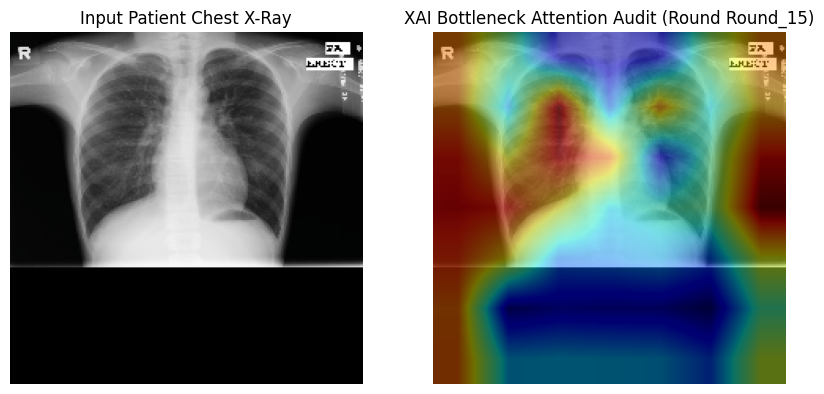

✓ Diagnostic visual proof saved successfully to Drive storage: /content/drive/My Drive/FedLungProject/attention_audit_round_Round_15.png



In [ ]:
import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch
import os
import re

def generate_and_save_attention_heatmap(round_num):
    # 1. Look for and load the saved global weights from Google Drive if available
    MODEL.eval()

    # Extract any number from the round_num string (e.g., "Round_15" -> "15")
    round_digits = re.findall(r'\d+', str(round_num))

    if round_digits:
        round_idx = round_digits[0]
        weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{round_idx}.pth"

        if os.path.exists(weight_file):
            print(f"📥 Found saved server weights! Loading: {weight_file}")
            MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
        else:
            print(f"⚠️ Warning: Expected weights file at '{weight_file}' but it wasn't found. Using current model state.")
    else:
        print("ℹ️ Generating baseline heatmap (No round number found, assuming Initial/Untrained state).")

    # 2. Pull a single sample chest X-ray image from your validation loader
    images, masks = next(iter(client0_val_loader))
    single_img = images[0:1].to(DEVICE) # Isolate single item as batch

    # 3. Run an evaluation forward pass to trigger attention storage hooks
    with torch.no_grad():
        _ = MODEL(single_img)

    # --- FIX: Dynamically handle whether it's stored as a list or a raw Tensor ---
    maps_data = MODEL.vit_bottleneck.extracted_attention_maps
    if isinstance(maps_data, list):
        attn_map = maps_data[-1].cpu().numpy() # If list, grab latest
    else:
        attn_map = maps_data[0].cpu().numpy()  # If Tensor, index the batch/head safely

    # Average the attention weights across all sequences to find overall regional focus
    mean_attn = np.mean(attn_map, axis=0) # Shape: [49]
    heatmap_grid = mean_attn.reshape(7, 7) # Reconstruct original 7x7 token configuration

    # Resize the heatmap up to 224x224 to match your source image size
    heatmap_resized = cv2.resize(heatmap_grid, (224, 224))
    heatmap_resized = (heatmap_resized - heatmap_resized.min()) / (heatmap_resized.max() - heatmap_resized.min() + 1e-8)

    # 5. Reverse-normalize the source chest X-ray to display it in viewable RGB colorspace
    src_img = single_img[0].permute(1, 2, 0).cpu().numpy()
    src_img = (src_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    src_img = np.clip(src_img, 0, 1)

    # 6. Render and plot the visual validation audit side-by-side
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(src_img)
    ax[0].set_title("Input Patient Chest X-Ray")
    ax[0].axis('off')

    # Overlay the attention heatmap onto the patient chest image
    ax[1].imshow(src_img)
    ax[1].imshow(heatmap_resized, cmap='jet', alpha=0.45) # Blend using jet color spectrum mappings
    ax[1].set_title(f"XAI Bottleneck Attention Audit (Round {round_num})")
    ax[1].axis('off')

    # 7. Save the generated explanation graphic directly to your Google Drive repository
    output_save_path = f"/content/drive/My Drive/FedLungProject/attention_audit_round_{round_num}.png"
    plt.savefig(output_save_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f"✓ Diagnostic visual proof saved successfully to Drive storage: {output_save_path}\n")

# --- EXECUTION ---
generate_and_save_attention_heatmap(round_num="Round_15")

📥 Loading server weights for validation comparison: /content/drive/My Drive/FedLungProject/global_model_round_15.pth


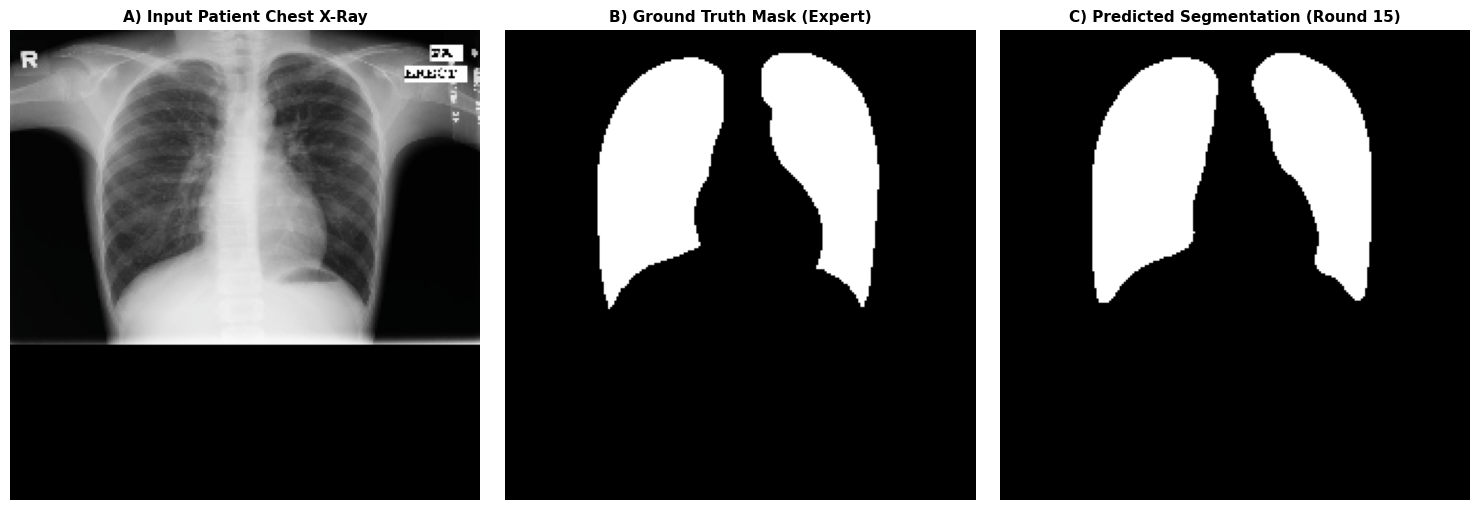

✓ Crisp diagnostic mask audit saved successfully to Drive storage: /content/drive/My Drive/FedLungProject/segmentation_audit_round_15.png



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

def visualize_final_segmentation_performance(round_num=15, threshold=0.5):
    """
    Loads model weights for a specific round, performs evaluation inference,
    and outputs a 3-panel comparison: Input X-Ray, Ground Truth Mask, and Model Prediction.
    """
    MODEL.eval()

    # 1. Load the specific server weights file
    weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{round_num}.pth"
    if os.path.exists(weight_file):
        print(f"📥 Loading server weights for validation comparison: {weight_file}")
        MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
    else:
        print(f"⚠️ Warning: Could not find weights at '{weight_file}'. Using current model memory instead.")

    # 2. Extract a clean sample pair from the validation dataloader
    images, masks = next(iter(client0_val_loader))
    single_img = images[0:1].to(DEVICE)  # Isolate as 1-item batch [1, C, H, W]

    # 3. Generate raw model predictions
    with torch.no_grad():
        outputs = MODEL(single_img)
        # Apply sigmoid to convert raw model logits into pixel probabilities between 0 and 1
        probs = torch.sigmoid(outputs)
        # Convert probabilities into a clean binary mask (0 or 1) based on standard threshold
        pred_mask = (probs > threshold).float()

    # 4. Process and reverse-normalize the source image back to viewable RGB
    src_img = single_img[0].permute(1, 2, 0).cpu().numpy()
    src_img = (src_img * np.array([0.229, 0.224, 0.225])) + np.array([0.485, 0.456, 0.406])
    src_img = np.clip(src_img, 0, 1)

    # 5. Extract the true ground truth mask and prediction array
    gt_mask = masks[0].cpu().numpy().squeeze()          # Squeezes out batch/channel dims -> [H, W]
    final_pred = pred_mask[0].cpu().numpy().squeeze()   # Squeezes out batch/channel dims -> [H, W]

    # 6. Build a beautiful 3-panel side-by-side scientific display
    fig, ax = plt.subplots(1, 3, figsize=(15, 5))

    # Panel A: Input Image
    ax[0].imshow(src_img)
    ax[0].set_title("A) Input Patient Chest X-Ray", fontsize=11, fontweight='bold')
    ax[0].axis('off')

    # Panel B: Expert Ground Truth Target
    ax[1].imshow(gt_mask, cmap='gray')
    ax[1].set_title("B) Ground Truth Mask (Expert)", fontsize=11, fontweight='bold')
    ax[1].axis('off')

    # Panel C: Fully Trained Machine Prediction
    ax[2].imshow(final_pred, cmap='gray')
    ax[2].set_title(f"C) Predicted Segmentation (Round {round_num})", fontsize=11, fontweight='bold')
    ax[2].axis('off')

    plt.tight_layout()

    # Save graphic output to your project folder
    output_save_path = f"/content/drive/My Drive/FedLungProject/segmentation_audit_round_{round_num}.png"
    plt.savefig(output_save_path, bbox_inches='tight', dpi=300)
    plt.show()
    print(f"✓ Crisp diagnostic mask audit saved successfully to Drive storage: {output_save_path}\n")

# --- EXECUTION ---
# Run this to see the accurate lung fields your model isolates at Round 15
visualize_final_segmentation_performance(round_num=15, threshold=0.5)

In [ ]:
import torch
import numpy as np
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def dice_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()
    union = pred.sum() + target.sum()

    return ((2.0 * intersection + smooth) /
            (union + smooth)).item()


def iou_score(pred, target, smooth=1e-6):
    pred = (pred > 0.5).float()

    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection

    return ((intersection + smooth) /
            (union + smooth)).item()

In [ ]:
from itertools import chain

def evaluate_combined(weight_path):

    model = TransUNetMini().to(device)

    model.load_state_dict(
        torch.load(weight_path, map_location=device)
    )

    model.eval()

    dice_scores = []
    iou_scores = []

    with torch.no_grad():

        for images, masks in chain(client0_val_loader,
                                   client1_val_loader):

            images = images.to(device)
            masks = masks.to(device)

            outputs = torch.sigmoid(model(images))

            dice_scores.append(
                dice_score(outputs, masks)
            )

            iou_scores.append(
                iou_score(outputs, masks)
            )

    return np.mean(dice_scores), np.mean(iou_scores)


In [ ]:
rounds = [3, 5, 10, 15]

for r in rounds:

    path = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"

    dice, iou = evaluate_combined(path)

    print("=" * 50)
    print(f"Round {r}")
    print(f"Dice : {dice:.4f}")
    print(f"IoU  : {iou:.4f}")

Round 3
Dice : 0.9427
IoU  : 0.8920
Round 5
Dice : 0.9528
IoU  : 0.9102
Round 10
Dice : 0.9580
IoU  : 0.9196
Round 15
Dice : 0.9588
IoU  : 0.9212


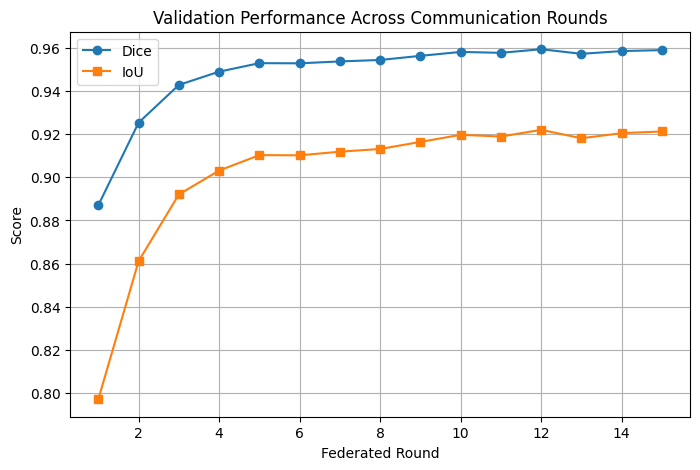

In [ ]:
import os
import matplotlib.pyplot as plt

round_list = []
dice_list = []
iou_list = []

for r in range(1, 16):

    path = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"

    if not os.path.exists(path):
        continue

    dice, iou = evaluate_combined(path)

    round_list.append(r)
    dice_list.append(dice)
    iou_list.append(iou)

plt.figure(figsize=(8,5))

plt.plot(round_list, dice_list, marker='o', label="Dice")
plt.plot(round_list, iou_list, marker='s', label="IoU")

plt.xlabel("Federated Round")
plt.ylabel("Score")
plt.title("Validation Performance Across Communication Rounds")
plt.grid(True)
plt.legend()

plt.show()

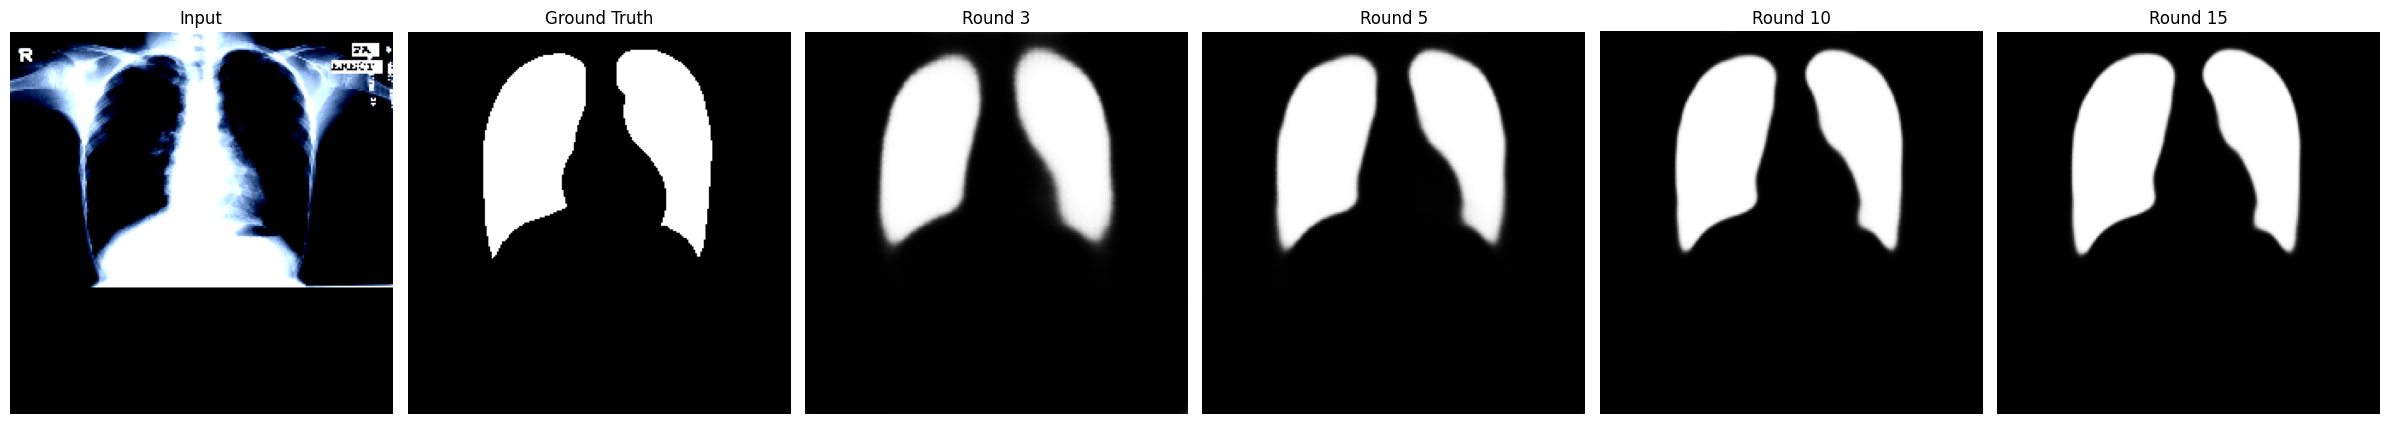

In [ ]:
import matplotlib.pyplot as plt

image, mask = client0_val_set[0]

image_batch = image.unsqueeze(0).to(device)

rounds = [3,5,10,15]

fig, axes = plt.subplots(1,6,figsize=(24,5))

axes[0].imshow(image.permute(1,2,0))
axes[0].set_title("Input")
axes[0].axis("off")

axes[1].imshow(mask.squeeze(), cmap='gray')
axes[1].set_title("Ground Truth")
axes[1].axis("off")

for i,r in enumerate(rounds):

    model = TransUNetMini().to(device)

    model.load_state_dict(
        torch.load(
            f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth",
            map_location=device
        )
    )

    model.eval()

    with torch.no_grad():

        pred = torch.sigmoid(model(image_batch))[0,0]

    axes[i+2].imshow(pred.cpu(), cmap='gray')
    axes[i+2].set_title(f"Round {r}")
    axes[i+2].axis("off")

plt.tight_layout()
plt.show()

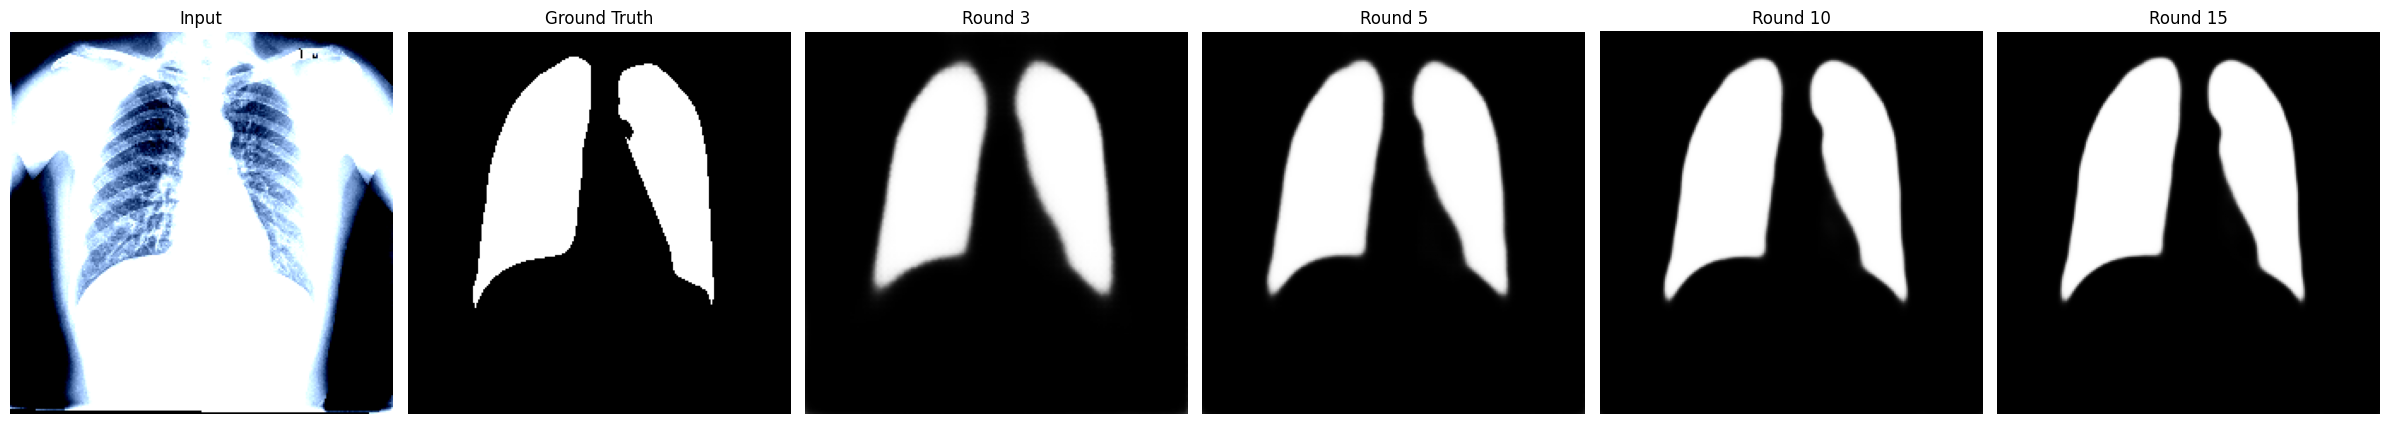

In [ ]:
image, mask = client1_val_set[0]

image_batch = image.unsqueeze(0).to(device)

rounds = [3,5,10,15]

fig, axes = plt.subplots(1,6,figsize=(24,5))

axes[0].imshow(image.permute(1,2,0))
axes[0].set_title("Input")
axes[0].axis("off")

axes[1].imshow(mask.squeeze(), cmap='gray')
axes[1].set_title("Ground Truth")
axes[1].axis("off")

for i,r in enumerate(rounds):

    model = TransUNetMini().to(device)

    model.load_state_dict(
        torch.load(
            f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth",
            map_location=device
        )
    )

    model.eval()

    with torch.no_grad():

        pred = torch.sigmoid(model(image_batch))[0,0]

    axes[i+2].imshow(pred.cpu(), cmap='gray')
    axes[i+2].set_title(f"Round {r}")
    axes[i+2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#XAI
import matplotlib.pyplot as plt
import cv2
import numpy as np
import torch
import os

def compare_attention_multiple_rounds(rounds=[0,3,5,10,15], sample_idx=0):

    # ------------------------------------
    # Select one fixed validation image
    # ------------------------------------
    image, mask = client0_val_set[sample_idx]
    single_img = image.unsqueeze(0).to(DEVICE)

    # Reverse normalization
    src_img = image.permute(1,2,0).cpu().numpy()
    src_img = src_img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])
    src_img = np.clip(src_img,0,1)

    # ------------------------------------
    # Create figure
    # ------------------------------------
    fig, axes = plt.subplots(
        1,
        len(rounds)+1,
        figsize=(5*(len(rounds)+1),5)
    )

    axes[0].imshow(src_img)
    axes[0].set_title("Input Image")
    axes[0].axis("off")

    # ------------------------------------
    # Loop through rounds
    # ------------------------------------
    for idx, round_num in enumerate(rounds):

        MODEL.eval()

        # Load model weights
        if round_num != 0:

            weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{round_num}.pth"

            if os.path.exists(weight_file):

                MODEL.load_state_dict(
                    torch.load(
                        weight_file,
                        map_location=DEVICE
                    )
                )

                print(f"Loaded Round {round_num}")

            else:

                print(f"Checkpoint not found: {weight_file}")
                continue

        else:

            print("Using Initial Model")

        # ------------------------------------
        # Clear previous attention
        # ------------------------------------
        MODEL.vit_bottleneck.extracted_attention_maps = None

        # ------------------------------------
        # Forward pass
        # ------------------------------------
        with torch.no_grad():
            _ = MODEL(single_img)

        maps = MODEL.vit_bottleneck.extracted_attention_maps

        # ------------------------------------
        # Handle list or tensor
        # ------------------------------------
        if isinstance(maps, list):
            maps = maps[-1]

        maps = maps.cpu().numpy()

        print(f"Round {round_num} Attention Shape: {maps.shape}")

        # ------------------------------------
        # Convert to (49×49)
        # ------------------------------------
        if maps.ndim == 4:
            attn = maps[0].mean(axis=0)

        elif maps.ndim == 3:
            attn = maps[0]

        elif maps.ndim == 2:
    # Shape = (49,49)
            attn = maps

        else:
            raise ValueError(f"Unexpected attention shape: {maps.shape}")

        # ------------------------------------
        # Center token attention
        # ------------------------------------
        center_token = 24

        heatmap = attn.mean(axis=0).reshape(7,7)

        heatmap = cv2.resize(
            heatmap,
            (224,224),
            interpolation=cv2.INTER_CUBIC
        )

        heatmap = (
            heatmap - heatmap.min()
        ) / (
            heatmap.max() - heatmap.min() + 1e-8
        )

        # ------------------------------------
        # Display
        # ------------------------------------
        axes[idx+1].imshow(src_img)
        axes[idx+1].imshow(
            heatmap,
            cmap='jet',
            alpha=0.45
        )

        if round_num == 0:
            axes[idx+1].set_title("Initial")
        else:
            axes[idx+1].set_title(f"Round {round_num}")

        axes[idx+1].axis("off")

        # ------------------------------------
        # Save
        # ------------------------------------
        plt.imsave(
            f"/content/drive/My Drive/FedLungProject/attention_round_{round_num}.png",
            heatmap,
            cmap="jet"
        )

    plt.tight_layout()
    plt.show()

    print("\n✓ Comparison completed successfully.")

Loaded Round 3
Round 3 Attention Shape: (1, 8, 49, 49)
Loaded Round 5
Round 5 Attention Shape: (1, 8, 49, 49)
Loaded Round 10
Round 10 Attention Shape: (1, 8, 49, 49)
Loaded Round 15
Round 15 Attention Shape: (1, 8, 49, 49)


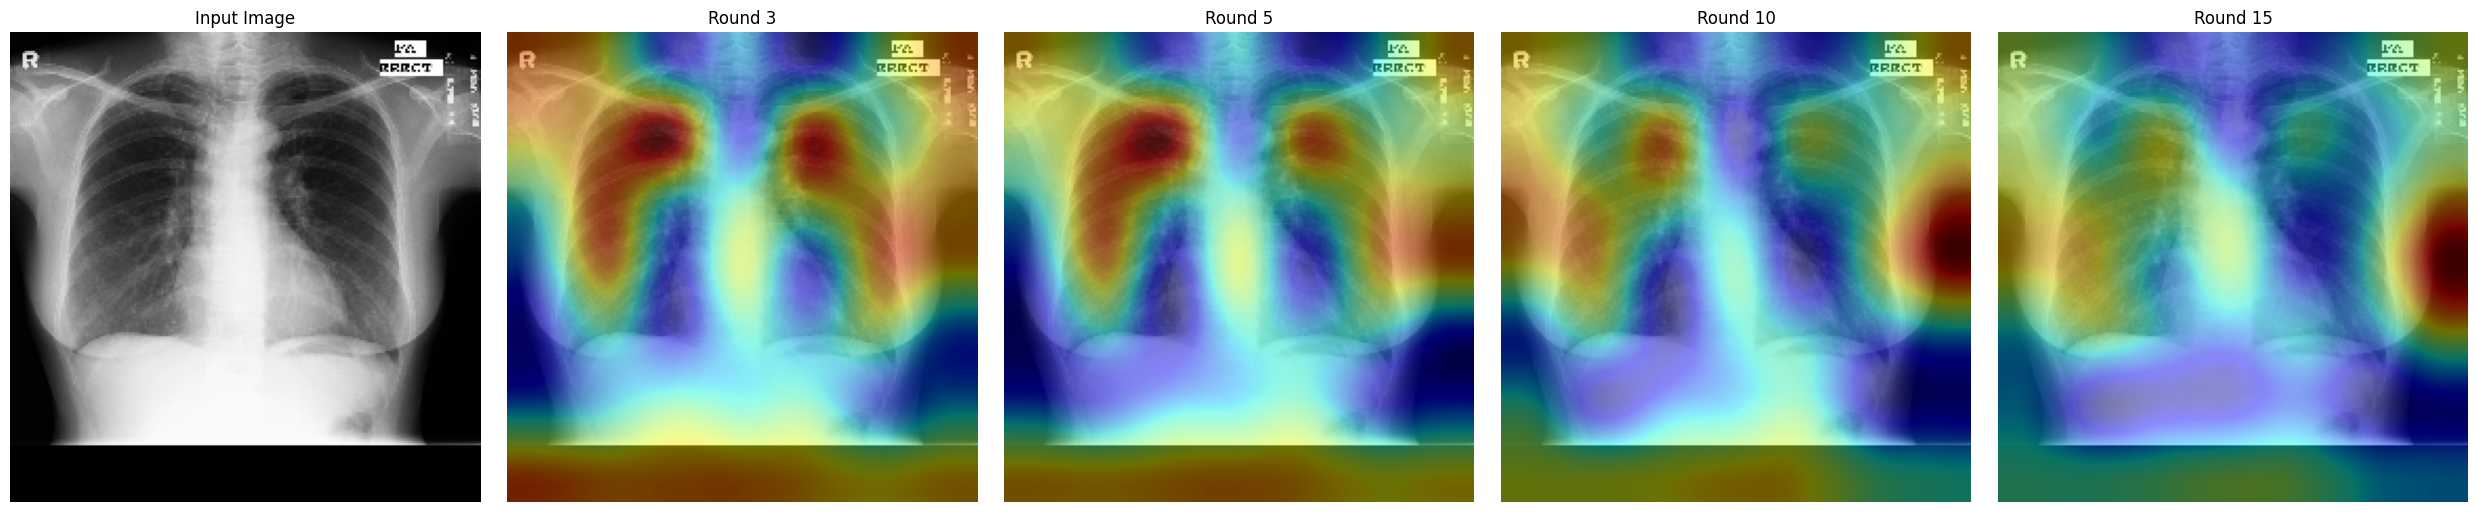


✓ Comparison completed successfully.


In [ ]:
compare_attention_multiple_rounds(
    rounds=[3,5,10,15],
    sample_idx=10
)

In [ ]:
!pip install -q grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 74.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import cv2

from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
MODEL = TransUNetMini().to(DEVICE)

In [ ]:
# ==========================
# Improved Grad-CAM++ for Segmentation
# ==========================

import matplotlib.pyplot as plt
import numpy as np
import cv2
import torch
import os

# ----------------------------
# Segmentation Target
# ----------------------------
class SegmentationTarget:

    def __init__(self, mask):
        self.mask = mask

    def __call__(self, model_output):

        prediction = torch.sigmoid(model_output)

        return (prediction * self.mask.to(prediction.device)).sum()


# ----------------------------------------------------
# Choose target layer
# Try changing to:
# MODEL.layer4
# MODEL.vit_bottleneck.proj
# MODEL.dec_conv1
# MODEL.dec_conv2   <-- Recommended
# MODEL.dec_conv3
# MODEL.dec_conv4
# ----------------------------------------------------

TARGET_LAYER = MODEL.dec_conv2


def compare_gradcampp(rounds=[3,5,10,15], sample_idx=0):

    image, gt_mask = client0_val_set[sample_idx]

    input_tensor = image.unsqueeze(0).to(DEVICE)

    gt_tensor = gt_mask.unsqueeze(0).to(DEVICE)

    rgb = image.permute(1,2,0).cpu().numpy()

    rgb = rgb * np.array([0.229,0.224,0.225]) + \
          np.array([0.485,0.456,0.406])

    rgb = np.clip(rgb,0,1)

    fig, axes = plt.subplots(
        1,
        len(rounds)+2,
        figsize=(5*(len(rounds)+2),5)
    )

    axes[0].imshow(rgb)
    axes[0].set_title("Input")
    axes[0].axis("off")

    axes[1].imshow(gt_mask.squeeze(), cmap="gray")
    axes[1].set_title("Ground Truth")
    axes[1].axis("off")

    for i,r in enumerate(rounds):

        weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"

        MODEL.load_state_dict(
            torch.load(weight_file, map_location=DEVICE)
        )

        MODEL.eval()

        cam = GradCAMPlusPlus(
            model=MODEL,
            target_layers=[TARGET_LAYER]
        )

        grayscale_cam = cam(
            input_tensor=input_tensor,
            targets=[SegmentationTarget(gt_tensor)]
        )[0]

        # Smooth heatmap
        grayscale_cam = cv2.GaussianBlur(
            grayscale_cam,
            (5,5),
            0
        )

        grayscale_cam = (
            grayscale_cam - grayscale_cam.min()
        ) / (
            grayscale_cam.max() - grayscale_cam.min() + 1e-8
        )

        visualization = show_cam_on_image(
            rgb.astype(np.float32),
            grayscale_cam,
            use_rgb=True
        )

        axes[i+2].imshow(visualization)
        axes[i+2].set_title(f"Round {r}")
        axes[i+2].axis("off")

        cv2.imwrite(
            f"/content/drive/My Drive/FedLungProject/GradCAMPP_Round_{r}.png",
            cv2.cvtColor(
                visualization,
                cv2.COLOR_RGB2BGR
            )
        )

    plt.tight_layout()
    plt.show()

    print("\n✓ Improved Grad-CAM++ completed successfully.")

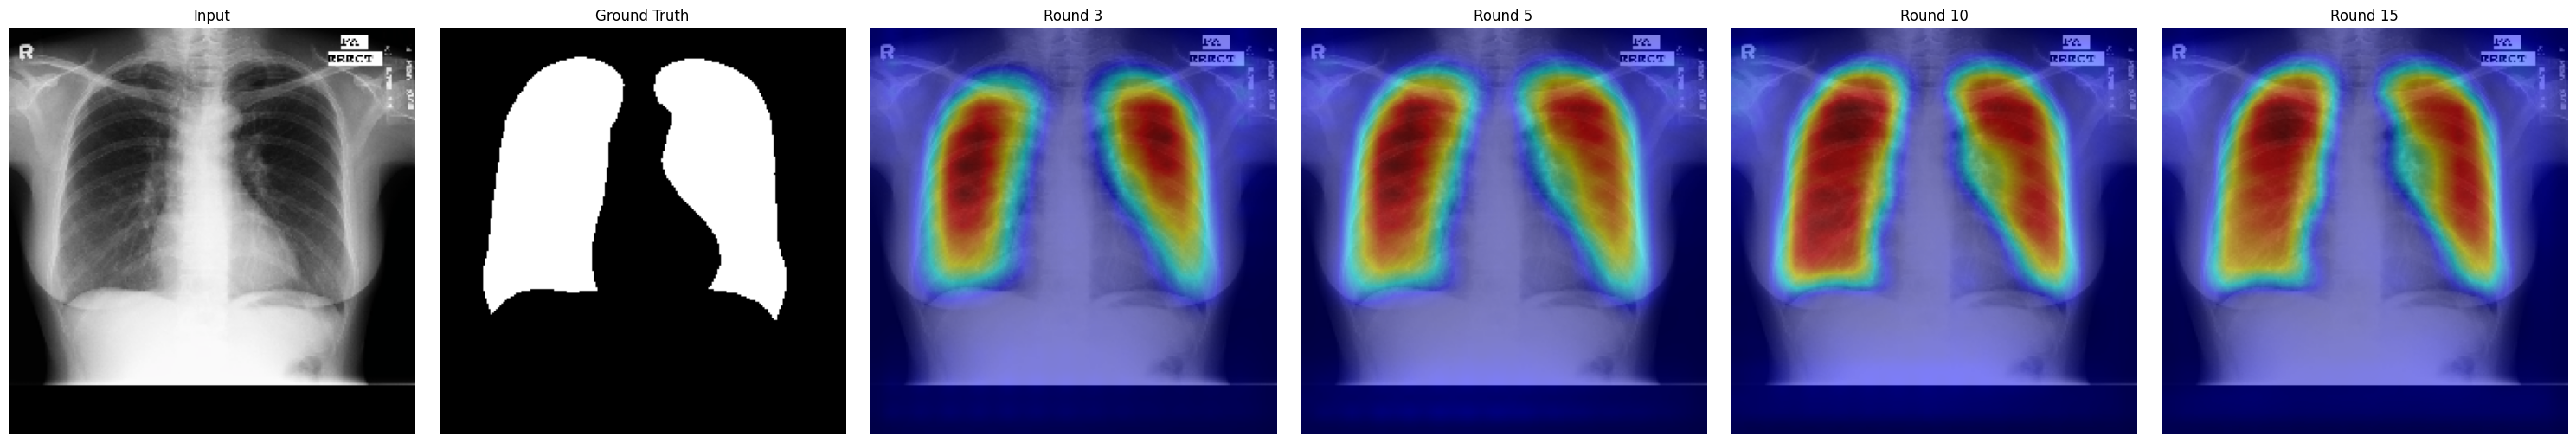


✓ Improved Grad-CAM++ completed successfully.


In [ ]:
compare_gradcampp(
    rounds=[3,5,10,15],
    sample_idx=10
)

In [ ]:
#F11
from torch.utils.data import ConcatDataset, DataLoader

# Pool both institutions into one dataset (this is what federated training is being compared against)
centralized_train_set = ConcatDataset([client0_train_set, client1_train_set])
centralized_val_set   = ConcatDataset([client0_val_set, client1_val_set])

centralized_train_loader = DataLoader(centralized_train_set, batch_size=8, shuffle=True)
centralized_val_loader   = DataLoader(centralized_val_set, batch_size=8, shuffle=False)

print(f"Centralized train: {len(centralized_train_set)}, val: {len(centralized_val_set)}")

Centralized train: 562, val: 142


In [ ]:
import torch.optim as optim

def compute_iou(preds, targets, threshold=0.5):
    preds = (torch.sigmoid(preds) > threshold).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return 1.0 if union == 0 else (intersection / union).item()

@torch.no_grad()
def evaluate_full(model, loader, device):
    model.eval()
    dice_sum, iou_sum, n = 0.0, 0.0, 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        dice_sum += compute_dice_coefficient(outputs, masks).item() * images.size(0)
        iou_sum  += compute_iou(outputs, masks) * images.size(0)
        n += images.size(0)
    return dice_sum / n, iou_sum / n

# Train centrally for the SAME total number of passes over data as the federated run:
# federated = 15 rounds x 1 local epoch per client → run 15 epochs centrally for a fair comparison
CENTRAL_MODEL = TransUNetMini().to(DEVICE)
central_optimizer = optim.Adam(CENTRAL_MODEL.parameters(), lr=1e-4)

central_history = []
for epoch in range(1, 16):
    train_loss, train_dice = train_local_epoch(CENTRAL_MODEL, centralized_train_loader, central_optimizer, DEVICE)
    val_dice, val_iou = evaluate_full(CENTRAL_MODEL, centralized_val_loader, DEVICE)
    central_history.append((epoch, val_dice, val_iou))
    print(f"[Centralized] Epoch {epoch:2d} | train_dice={train_dice:.4f} | val_dice={val_dice:.4f} | val_iou={val_iou:.4f}")

torch.save(CENTRAL_MODEL.state_dict(), "/content/drive/My Drive/FedLungProject/centralized_model_final.pth")

KeyboardInterrupt: 

In [ ]:
class ResNet34UNetBaseline(nn.Module):
    """Same encoder/decoder as TransUNetMini but WITHOUT the ViT bottleneck."""
    def __init__(self):
        super().__init__()
        base_resnet = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.init_conv = nn.Sequential(base_resnet.conv1, base_resnet.bn1, base_resnet.relu, base_resnet.maxpool)
        self.layer1 = base_resnet.layer1
        self.layer2 = base_resnet.layer2
        self.layer3 = base_resnet.layer3
        self.layer4 = base_resnet.layer4
        # No bottleneck here — x4 goes straight to the decoder

        self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec_conv1 = nn.Sequential(nn.Conv2d(512, 256, 3, padding=1), nn.ReLU(inplace=True))
        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec_conv2 = nn.Sequential(nn.Conv2d(256, 128, 3, padding=1), nn.ReLU(inplace=True))
        self.up3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec_conv3 = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.ReLU(inplace=True))
        self.up4 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec_conv4 = nn.Sequential(nn.Conv2d(32, 32, 3, padding=1), nn.ReLU(inplace=True))
        self.final_mask_projection = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        x0 = self.init_conv(x)
        x1 = self.layer1(x0); x2 = self.layer2(x1); x3 = self.layer3(x2); x4 = self.layer4(x3)
        d1 = self.dec_conv1(torch.cat([self.up1(x4), x3], dim=1))
        d2 = self.dec_conv2(torch.cat([self.up2(d1), x2], dim=1))
        d3 = self.dec_conv3(torch.cat([self.up3(d2), x1], dim=1))
        d4 = self.dec_conv4(self.up4(d3))
        d5 = F.interpolate(d4, scale_factor=2, mode='bilinear', align_corners=True)
        return self.final_mask_projection(d5)

In [ ]:
import flwr as fl
import torch
import collections

# 1. Define the metric aggregator (moved from an earlier cell for scope)
def aggregate_metrics(metrics):
    total_examples = sum([num_examples for num_examples, _ in metrics])
    weighted_dice = sum([num_examples * m["dice"] for num_examples, m in metrics])
    return {"dice": weighted_dice / total_examples}

def client_fn_ablation(cid: str) -> fl.client.Client:
    local_model = ResNet34UNetBaseline().to(DEVICE)
    if cid == "0":
        return FlowerClient(local_model, client0_train_loader, client0_val_loader, DEVICE).to_client()
    elif cid == "1":
        return FlowerClient(local_model, client1_train_loader, client1_val_loader, DEVICE).to_client()

def get_evaluate_fn_ablation():
    def evaluate(server_round, parameters, config):
        temp_model = ResNet34UNetBaseline()
        params_dict = zip(temp_model.state_dict().keys(), parameters)
        state_dict = collections.OrderedDict({k: torch.tensor(v) for k, v in params_dict})
        temp_model.load_state_dict(state_dict, strict=True)
        torch.save(temp_model.state_dict(), f"/content/drive/My Drive/FedLungProject/ablation_noViT_round_{server_round}.pth")
        return 0.0, {}
    return evaluate

strategy_ablation = fl.server.strategy.FedAvg(
    fraction_fit=1.0, fraction_evaluate=1.0,
    min_fit_clients=2, min_evaluate_clients=2, min_available_clients=2,
    evaluate_metrics_aggregation_fn=aggregate_metrics,
    evaluate_fn=get_evaluate_fn_ablation()
)
history_ablation = fl.simulation.start_simulation(
    client_fn=client_fn_ablation, num_clients=2,
    config=fl.server.ServerConfig(num_rounds=15), strategy=strategy_ablation,
    client_resources={"num_gpus": 0.5 if torch.cuda.is_available() else 0, "num_cpus": 1}
)

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

          

Round 3: mean attention-in-mask fraction = 0.3037
Round 5: mean attention-in-mask fraction = 0.3039
Round 10: mean attention-in-mask fraction = 0.2675
Round 15: mean attention-in-mask fraction = 0.2782


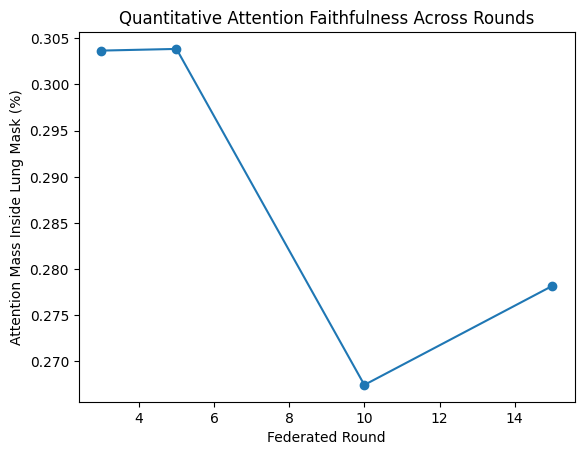

In [ ]:
@torch.no_grad()
def attention_mass_in_mask(model, val_loader, device):
    """Fraction of attention heatmap energy that falls inside the GT lung mask, averaged over a loader."""
    model.eval()
    scores = []
    for images, masks in val_loader:
        images = images.to(device)
        for i in range(images.size(0)):
            single_img = images[i:i+1]
            gt_mask = masks[i, 0].cpu().numpy()  # [224,224], values in {0,1}

            model.vit_bottleneck.extracted_attention_maps = None
            _ = model(single_img)
            maps = model.vit_bottleneck.extracted_attention_maps
            if isinstance(maps, list):
                maps = maps[-1]
            attn = maps[0].cpu().numpy()          # [heads, 49, 49] or [49,49]
            if attn.ndim == 3:
                attn = attn.mean(axis=0)
            heatmap = attn.mean(axis=0).reshape(7, 7)
            heatmap = cv2.resize(heatmap, (224, 224), interpolation=cv2.INTER_CUBIC)
            heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

            inside = (heatmap * gt_mask).sum()
            total = heatmap.sum() + 1e-8
            scores.append(inside / total)
    return float(np.mean(scores))

pooled_val_loader = DataLoader(ConcatDataset([client0_val_set, client1_val_set]), batch_size=8, shuffle=False)

xai_results = {}
for r in [3, 5, 10, 15]:
    weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"
    MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
    score = attention_mass_in_mask(MODEL, pooled_val_loader, DEVICE)
    xai_results[r] = score
    print(f"Round {r}: mean attention-in-mask fraction = {score:.4f}")

plt.plot(list(xai_results.keys()), list(xai_results.values()), marker='o')
plt.xlabel("Federated Round"); plt.ylabel("Attention Mass Inside Lung Mask (%)")
plt.title("Quantitative Attention Faithfulness Across Rounds")
plt.show()

In [ ]:
total_params = sum(p.numel() for p in MODEL.parameters())
size_mb = total_params * 4 / 1e6  # float32
print(f"Total parameters: {total_params:,} ({size_mb:.1f} MB per checkpoint)")
print(f"Estimated communication per round (2 clients, up+down): {4*size_mb:.1f} MB")
print(f"Estimated total communication over 15 rounds: {15*4*size_mb/1000:.2f} GB")

Total parameters: 25,116,449 (100.5 MB per checkpoint)
Estimated communication per round (2 clients, up+down): 401.9 MB
Estimated total communication over 15 rounds: 6.03 GB


In [ ]:
final_round_dices = []
final_round_ious = []

for run_seed in [0, 1, 2]:
    torch.manual_seed(run_seed)
    print(f"\n=== Federated run, seed={run_seed} ===")

    def get_evaluate_fn_seeded(seed):
        def evaluate(server_round, parameters, config):
            temp_model = TransUNetMini()
            params_dict = zip(temp_model.state_dict().keys(), parameters)
            state_dict = collections.OrderedDict({k: torch.tensor(v) for k, v in params_dict})
            temp_model.load_state_dict(state_dict, strict=True)
            if server_round == 15:
                dice, iou = evaluate_full(temp_model.to(DEVICE), pooled_val_loader, DEVICE)
                final_round_dices.append(dice)
                final_round_ious.append(iou)
                torch.save(temp_model.state_dict(), f"/content/drive/My Drive/FedLungProject/seed{seed}_round_{server_round}.pth")
            return 0.0, {}
        return evaluate

    strategy_seeded = fl.server.strategy.FedAvg(
        fraction_fit=1.0, fraction_evaluate=1.0,
        min_fit_clients=2, min_evaluate_clients=2, min_available_clients=2,
        evaluate_metrics_aggregation_fn=aggregate_metrics,
        evaluate_fn=get_evaluate_fn_seeded(run_seed)
    )
    fl.simulation.start_simulation(
        client_fn=client_fn, num_clients=2,
        config=fl.server.ServerConfig(num_rounds=15), strategy=strategy_seeded,
        client_resources={"num_gpus": 0.5 if torch.cuda.is_available() else 0, "num_cpus": 1}
    )

print(f"\nFinal-round Dice: mean={np.mean(final_round_dices):.4f}, std={np.std(final_round_dices):.4f}")
print(f"Final-round IoU:  mean={np.mean(final_round_ious):.4f}, std={np.std(final_round_ious):.4f}")

	Instead, use the `flwr run` CLI command to start a local simulation in your Flower app, as shown for example below:

		$ flwr new  # Create a new Flower app from a template

		$ flwr run  # Run the Flower app in Simulation Mode

	Using `start_simulation()` is deprecated.

            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
INFO :      Starting Flower simulation, config: num_rounds=15, no round_timeout



=== Federated run, seed=0 ===


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026-07-17 18:43:59,541	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'memory': 9262234420.0, 'GPU': 1.0, 'CPU': 2.0, 'node:172.28.0.12': 1.0, 'accelerator_type:T4': 1.0, 'object_store_memory': 3969529036.0, 'node:__internal_head__': 1.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_gpus': 0.5, 'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(ClientAp


=== Federated run, seed=1 ===


2026-07-17 19:21:04,605	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'object_store_memory': 3979199692.0, 'node:__internal_head__': 1.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'accelerator_type:T4': 1.0, 'CPU': 2.0, 'memory': 9284799284.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_gpus': 0.5, 'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(ClientAppActor pid=57204) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=57204) 
(ClientAppActor pid=57204)   


=== Federated run, seed=2 ===


2026-07-17 19:57:50,514	INFO worker.py:2012 -- Started a local Ray instance.
INFO :      Flower VCE: Ray initialized with resources: {'node:__internal_head__': 1.0, 'CPU': 2.0, 'GPU': 1.0, 'node:172.28.0.12': 1.0, 'accelerator_type:T4': 1.0, 'object_store_memory': 3978461184.0, 'memory': 9283076096.0}
INFO :      Optimize your simulation with Flower VCE: https://flower.ai/docs/framework/how-to-run-simulations.html
INFO :      Flower VCE: Resources for each Virtual Client: {'num_gpus': 0.5, 'num_cpus': 1}
INFO :      Flower VCE: Creating VirtualClientEngineActorPool with 2 actors
INFO :      [INIT]
INFO :      Requesting initial parameters from one random client
(ClientAppActor pid=66718) WARNING :   DEPRECATED FEATURE: `client_fn` now expects a signature `def client_fn(context: Context)`.The provided `client_fn` has signature: {'cid': <Parameter "cid: str">}. You can import the `Context` like this: `from flwr.app import Context`
(ClientAppActor pid=66718) 
(ClientAppActor pid=66718)   


Final-round Dice: mean=0.9593, std=0.0004
Final-round IoU:  mean=0.9220, std=0.0007


/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
from google.colab import files
uploaded = files.upload()  # upload kaggle.json when prompted

import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json
!pip install -q kaggle

Saving kaggle.json to kaggle.json


In [ ]:
JSRT_DIR = '/content/drive/My Drive/FedLungProject/jsrt_external'
os.makedirs(JSRT_DIR, exist_ok=True)

!kaggle datasets download -d abduzzami/jsrt-247-image-lung-segmentation-mask-dataset -p "{JSRT_DIR}" --unzip

print("Contents:", os.listdir(JSRT_DIR))

Dataset URL: https://www.kaggle.com/datasets/abduzzami/jsrt-247-image-lung-segmentation-mask-dataset
License(s): apache-2.0
100% 16.3M/16.3M [00:01<00:00, 12.8MB/s]

Contents: ['content']


In [ ]:
import os

JSRT_DIR = '/content/drive/My Drive/FedLungProject/jsrt_external'

for root, dirs, files in os.walk(JSRT_DIR):
    level = root.replace(JSRT_DIR, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")
    if level < 4:  # don't spam if it's deeply nested
        for f in files[:5]:
            print(f"{indent}  {f}")
        if len(files) > 5:
            print(f"{indent}  ... ({len(files)} files total)")

jsrt_external/
  content/
    jsrt/
      cxr/
        JPCLN001.png
        JPCLN002.png
        JPCLN003.png
        JPCLN004.png
        JPCLN005.png
        ... (247 files total)
      masks/
        JPCLN001.png
        JPCLN002.png
        JPCLN003.png
        JPCLN004.png
        JPCLN005.png
        ... (247 files total)


In [ ]:
JSRT_DIR = '/content/drive/My Drive/FedLungProject/jsrt_external'
os.makedirs(JSRT_DIR, exist_ok=True)

!kaggle datasets download -d abduzzami/jsrt-247-image-lung-segmentation-mask-dataset -p "{JSRT_DIR}" --unzip

JSRT_IMG_DIR = os.path.join(JSRT_DIR, 'content', 'jsrt', 'cxr')
JSRT_MASK_DIR = os.path.join(JSRT_DIR, 'content', 'jsrt', 'masks')
print(f"Images: {len(os.listdir(JSRT_IMG_DIR))}")
print(f"Masks:  {len(os.listdir(JSRT_MASK_DIR))}")

Dataset URL: https://www.kaggle.com/datasets/abduzzami/jsrt-247-image-lung-segmentation-mask-dataset
License(s): apache-2.0
100% 16.3M/16.3M [00:00<00:00, 17.3MB/s]

Images: 247
Masks:  247


In [ ]:
import glob

class JSRTExternalDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_paths = sorted(glob.glob(os.path.join(image_dir, '*.png')))
        self.mask_dir = mask_dir
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        fname = os.path.basename(img_path)
        mask_path = os.path.join(self.mask_dir, fname)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask is None:
            raise FileNotFoundError(f"No mask found for {fname}")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask']

        mask = (mask > 0).float().unsqueeze(0)
        return image, mask

jsrt_transforms = A.Compose([
    A.Resize(224, 224),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

jsrt_dataset = JSRTExternalDataset(
    image_dir=JSRT_IMG_DIR,
    mask_dir=JSRT_MASK_DIR,
    transform=jsrt_transforms
)
jsrt_loader = DataLoader(jsrt_dataset, batch_size=8, shuffle=False)
print(f"JSRT external test set: {len(jsrt_dataset)} images")

JSRT external test set: 247 images


Image shape: torch.Size([3, 224, 224]), Mask shape: torch.Size([1, 224, 224])
Raw mask unique values: [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  70  71  72
  73  75  76  77  78  79  80  81  82  83  85  86  87  88  89  90  91  92
  93  94  95  96  98  99 100 101 102 103 104 105 106 107 108 109 110 111
 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127 128 129
 131 132 133 134 135 136 137 138 139 140 141 142 143 144 145 146 147 149
 150 151 152 153 154 155 156 157 158 159 160 161 163 164 165 166 167 168
 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186
 187 189 190 191 192 193 194 195 196 197 198 199 200 201 202 203 204 205
 206 207 208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223
 224 225 226 227 228 2

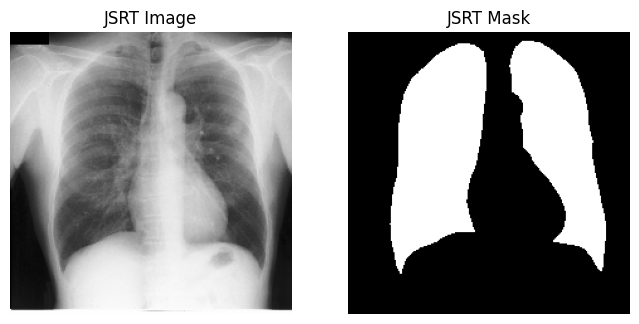

In [ ]:
sample_img, sample_mask = jsrt_dataset[0]
raw_mask = cv2.imread(os.path.join(JSRT_MASK_DIR, os.path.basename(jsrt_dataset.image_paths[0])), cv2.IMREAD_GRAYSCALE)
print(f"Image shape: {sample_img.shape}, Mask shape: {sample_mask.shape}")
print(f"Raw mask unique values: {np.unique(raw_mask)}")

fig, ax = plt.subplots(1, 2, figsize=(8,4))
img_vis = sample_img.permute(1,2,0).numpy()
img_vis = (img_vis * np.array([0.229,0.224,0.225])) + np.array([0.485,0.456,0.406])
ax[0].imshow(np.clip(img_vis,0,1)); ax[0].set_title("JSRT Image"); ax[0].axis('off')
ax[1].imshow(sample_mask.squeeze().numpy(), cmap='gray'); ax[1].set_title("JSRT Mask"); ax[1].axis('off')
plt.show()

In [ ]:
# Federated global model, final round
MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/global_model_round_15.pth", map_location=DEVICE))
fed_dice, fed_iou = evaluate_full(MODEL, jsrt_loader, DEVICE)
print(f"[Federated → JSRT]   Dice={fed_dice:.4f}, IoU={fed_iou:.4f}")

# Centralized model, for comparison
CENTRAL_MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/centralized_model_final.pth", map_location=DEVICE))
cent_dice, cent_iou = evaluate_full(CENTRAL_MODEL, jsrt_loader, DEVICE)
print(f"[Centralized → JSRT] Dice={cent_dice:.4f}, IoU={cent_iou:.4f}")

# For reference, print your in-distribution numbers again so you can compare the drop directly
print(f"\n[Federated → Montgomery+Shenzhen val] Dice≈0.9588–0.9600 (from earlier runs)")

NameError: name 'evaluate_full' is not defined

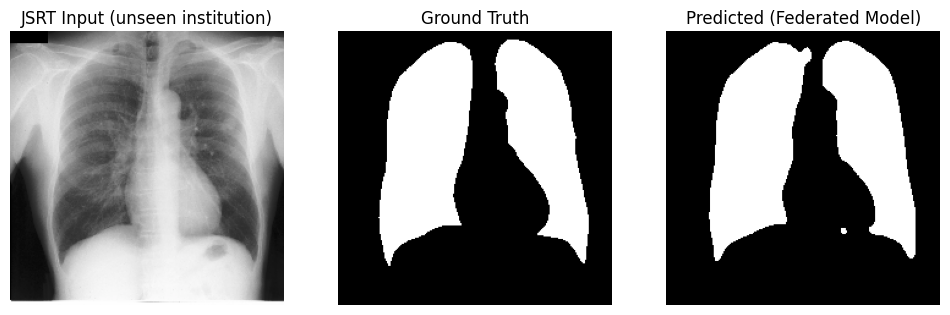

In [ ]:
MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/global_model_round_15.pth", map_location=DEVICE))
MODEL.eval()
images, masks = next(iter(jsrt_loader))
with torch.no_grad():
    preds = (torch.sigmoid(MODEL(images.to(DEVICE))) > 0.5).float()

fig, ax = plt.subplots(1, 3, figsize=(12, 4))
img = images[0].permute(1,2,0).numpy()
img = (img * np.array([0.229,0.224,0.225])) + np.array([0.485,0.456,0.406])
ax[0].imshow(np.clip(img,0,1)); ax[0].set_title("JSRT Input (unseen institution)"); ax[0].axis('off')
ax[1].imshow(masks[0,0].numpy(), cmap='gray'); ax[1].set_title("Ground Truth"); ax[1].axis('off')
ax[2].imshow(preds[0,0].cpu().numpy(), cmap='gray'); ax[2].set_title("Predicted (Federated Model)"); ax[2].axis('off')
plt.savefig("/content/drive/My Drive/FedLungProject/jsrt_external_qualitative.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
fed_dice_by_round = {}
fed_iou_by_round = {}

for r in range(0, 16):
    ckpt_path = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"
    if os.path.exists(ckpt_path):
        MODEL.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
        dice, iou = evaluate_full(MODEL, pooled_val_loader, DEVICE)
        fed_dice_by_round[r] = dice
        fed_iou_by_round[r] = iou
        print(f"Round {r:2d}: Dice={dice:.4f}, IoU={iou:.4f}")
    else:
        print(f"Round {r:2d}: checkpoint not found, skipping")

print(f"\nFinal round ({max(fed_dice_by_round.keys())}): Dice={fed_dice_by_round[max(fed_dice_by_round.keys())]:.4f}, "
      f"IoU={fed_iou_by_round[max(fed_dice_by_round.keys())]:.4f}")

Round  0: Dice=0.0000, IoU=0.0000
Round  1: Dice=0.8886, IoU=0.7996
Round  2: Dice=0.9270, IoU=0.8641
Round  3: Dice=0.9447, IoU=0.8954
Round  4: Dice=0.9511, IoU=0.9069
Round  5: Dice=0.9548, IoU=0.9137
Round  6: Dice=0.9550, IoU=0.9141
Round  7: Dice=0.9561, IoU=0.9161
Round  8: Dice=0.9565, IoU=0.9169
Round  9: Dice=0.9577, IoU=0.9191
Round 10: Dice=0.9592, IoU=0.9217
Round 11: Dice=0.9583, IoU=0.9202
Round 12: Dice=0.9602, IoU=0.9237
Round 13: Dice=0.9585, IoU=0.9205
Round 14: Dice=0.9596, IoU=0.9225
Round 15: Dice=0.9600, IoU=0.9232

Final round (15): Dice=0.9600, IoU=0.9232


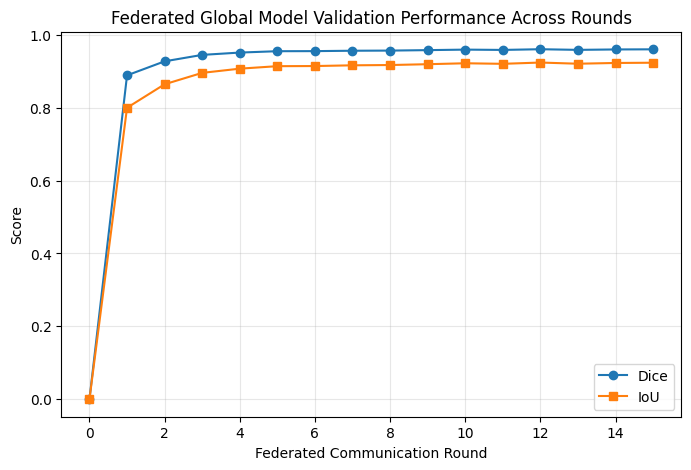

In [ ]:
rounds_sorted = sorted(fed_dice_by_round.keys())
dice_vals = [fed_dice_by_round[r] for r in rounds_sorted]
iou_vals = [fed_iou_by_round[r] for r in rounds_sorted]

plt.figure(figsize=(8,5))
plt.plot(rounds_sorted, dice_vals, marker='o', label='Dice', color='#1f77b4')
plt.plot(rounds_sorted, iou_vals, marker='s', label='IoU', color='#ff7f0e')
plt.xlabel("Federated Communication Round")
plt.ylabel("Score")
plt.title("Federated Global Model Validation Performance Across Rounds")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/fig2_updated_dice_iou.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
# Compute the missing ablation IoU (and re-confirm Dice) directly from the saved checkpoint
ABLATION_MODEL = ResNet34UNetBaseline().to(DEVICE)
ABLATION_MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/ablation_noViT_round_15.pth", map_location=DEVICE))
ablation_dice, ablation_iou = evaluate_full(ABLATION_MODEL, pooled_val_loader, DEVICE)
print(f"[Ablation, no ViT] Dice={ablation_dice:.4f}, IoU={ablation_iou:.4f}")

NameError: name 'evaluate_full' is not defined

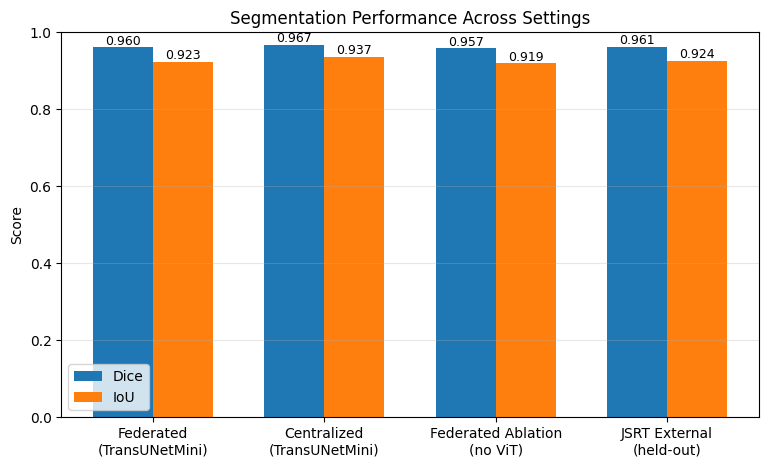

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
final_round = max(fed_dice_by_round.keys())

labels = ['Federated\n(TransUNetMini)', 'Centralized\n(TransUNetMini)', 'Federated Ablation\n(no ViT)', 'JSRT External\n(held-out)']
dice_scores = [fed_dice_by_round[final_round], cent_dice, ablation_dice, fed_dice]
iou_scores  = [fed_iou_by_round[final_round], cent_iou, ablation_iou, fed_iou]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9,5))
bars1 = ax.bar(x - width/2, dice_scores, width, label='Dice', color='#1f77b4')
bars2 = ax.bar(x + width/2, iou_scores, width, label='IoU', color='#ff7f0e')

ax.set_ylabel('Score')
ax.set_title('Segmentation Performance Across Settings')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax.annotate(f'{bar.get_height():.3f}', (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.annotate(f'{bar.get_height():.3f}', (bar.get_x()+bar.get_width()/2, bar.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.savefig("/content/drive/My Drive/FedLungProject/comparison_bar_chart.png", dpi=300, bbox_inches='tight')
plt.show()

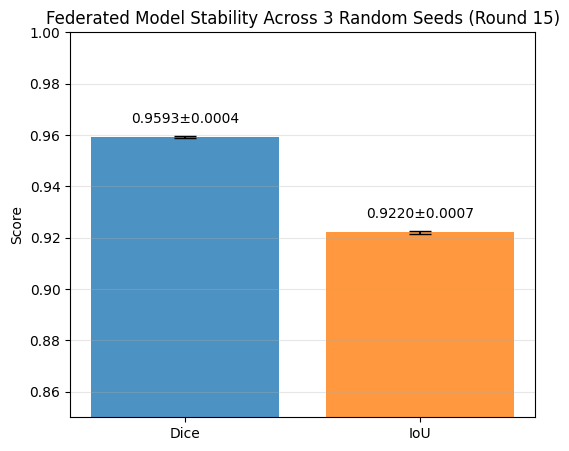

In [ ]:
plt.figure(figsize=(6,5))
metrics = ['Dice', 'IoU']
means = [np.mean(final_round_dices), np.mean(final_round_ious)]
stds = [np.std(final_round_dices), np.std(final_round_ious)]

plt.bar(metrics, means, yerr=stds, capsize=8, color=['#1f77b4', '#ff7f0e'], alpha=0.8)
for i, (m, s) in enumerate(zip(means, stds)):
    plt.text(i, m + s + 0.005, f'{m:.4f}±{s:.4f}', ha='center', fontsize=10)
plt.ylim(0.85, 1.0)
plt.ylabel('Score')
plt.title('Federated Model Stability Across 3 Random Seeds (Round 15)')
plt.grid(axis='y', alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/multiseed_variance.png", dpi=300, bbox_inches='tight')
plt.show()

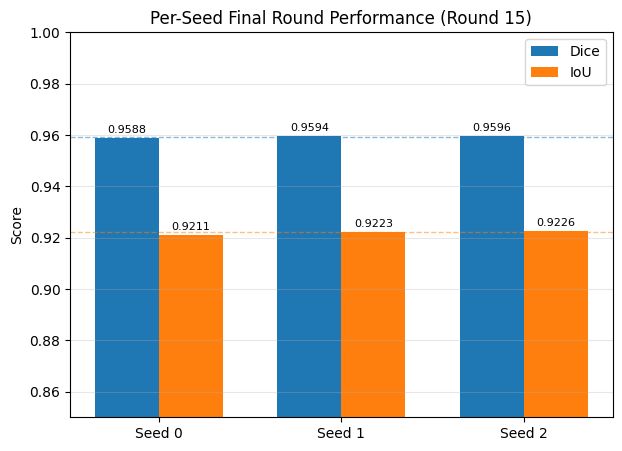

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
plt.figure(figsize=(7,5))
seeds = [0, 1, 2]
x = np.arange(len(seeds))
width = 0.35

bars1 = plt.bar(x - width/2, final_round_dices, width, label='Dice', color='#1f77b4')
bars2 = plt.bar(x + width/2, final_round_ious, width, label='IoU', color='#ff7f0e')

plt.axhline(np.mean(final_round_dices), color='#1f77b4', linestyle='--', alpha=0.5, linewidth=1)
plt.axhline(np.mean(final_round_ious), color='#ff7f0e', linestyle='--', alpha=0.5, linewidth=1)

plt.xticks(x, [f'Seed {s}' for s in seeds])
plt.ylabel('Score')
plt.ylim(0.85, 1.0)
plt.title('Per-Seed Final Round Performance (Round 15)')
plt.legend()
plt.grid(axis='y', alpha=0.3)

for bar in bars1:
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002, f'{bar.get_height():.4f}', ha='center', fontsize=8)
for bar in bars2:
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002, f'{bar.get_height():.4f}', ha='center', fontsize=8)

plt.savefig("/content/drive/My Drive/FedLungProject/multiseed_scatter.png", dpi=300, bbox_inches='tight')
plt.show()

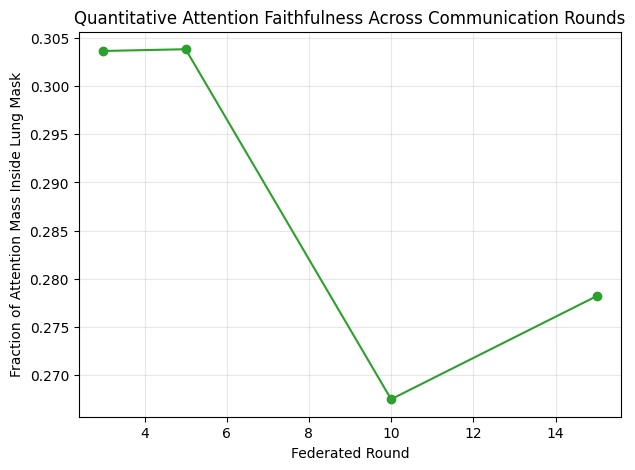

In [ ]:
plt.figure(figsize=(7,5))
rounds_xai = list(xai_results.keys())
scores_xai = list(xai_results.values())
plt.plot(rounds_xai, scores_xai, marker='o', color='#2ca02c')
plt.xlabel("Federated Round")
plt.ylabel("Fraction of Attention Mass Inside Lung Mask")
plt.title("Quantitative Attention Faithfulness Across Communication Rounds")
plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/xai_quantitative.png", dpi=300, bbox_inches='tight')
plt.show()

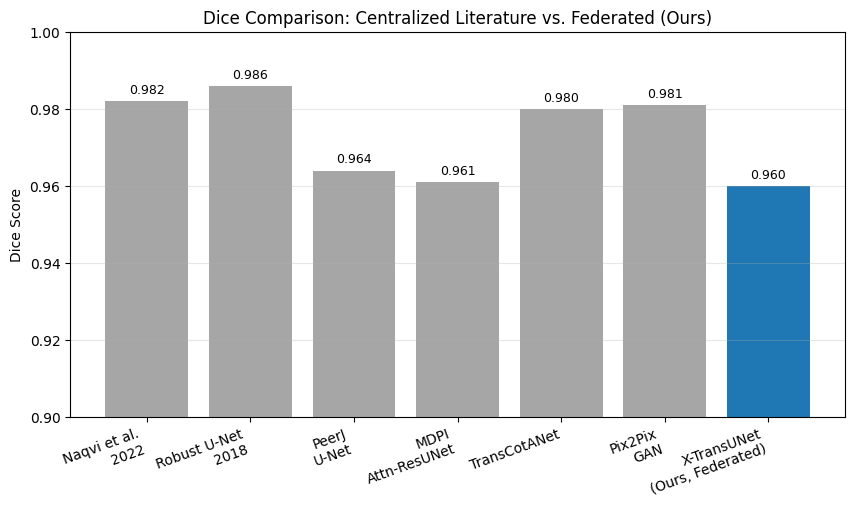

In [ ]:
lit_studies = ['Naqvi et al.\n2022', 'Robust U-Net\n2018', 'PeerJ\nU-Net', 'MDPI\nAttn-ResUNet', 'TransCotANet', 'Pix2Pix\nGAN', 'X-TransUNet\n(Ours, Federated)']
lit_dice =    [0.982,           0.986,             0.964,        0.961,             0.980,          0.981,       fed_dice_by_round[final_round]]
colors = ['#a6a6a6']*6 + ['#1f77b4']  # highlight your own bar

plt.figure(figsize=(10,5))
bars = plt.bar(lit_studies, lit_dice, color=colors)
plt.ylabel('Dice Score')
plt.title('Dice Comparison: Centralized Literature vs. Federated (Ours)')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20, ha='right')
for bar in bars:
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002, f'{bar.get_height():.3f}', ha='center', fontsize=9)
plt.grid(axis='y', alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/literature_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
gradcam_activations = {}
gradcam_gradients = {}

def _save_activation(module, input, output):
    gradcam_activations['value'] = output

def _save_gradient(module, grad_input, grad_output):
    gradcam_gradients['value'] = grad_output[0]

# Hook the same layer your paper will describe (dec_conv2 — see earlier fix)
h1 = MODEL.dec_conv2.register_forward_hook(_save_activation)
h2 = MODEL.dec_conv2.register_full_backward_hook(_save_gradient)

def gradcam_mass_in_mask(model, val_loader, device):
    model.eval()
    scores = []
    for images, masks in val_loader:
        for i in range(images.size(0)):
            single_img = images[i:i+1].to(device).requires_grad_(True)
            gt_mask = masks[i, 0].cpu().numpy()

            output = model(single_img)
            model.zero_grad()
            output.sum().backward()

            acts = gradcam_activations['value'][0].detach().cpu().numpy()   # [C, h, w]
            grads = gradcam_gradients['value'][0].detach().cpu().numpy()    # [C, h, w]
            weights = grads.mean(axis=(1, 2))                              # GAP over spatial dims (standard Grad-CAM weighting)
            cam = np.maximum((weights[:, None, None] * acts).sum(axis=0), 0)  # ReLU

            cam = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_CUBIC)
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

            inside = (cam * gt_mask).sum()
            total = cam.sum() + 1e-8
            scores.append(inside / total)
    return float(np.mean(scores))

gradcam_results = {}
for r in [3, 5, 10, 15]:
    weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"
    MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
    score = gradcam_mass_in_mask(MODEL, pooled_val_loader, DEVICE)
    gradcam_results[r] = score
    print(f"Round {r}: Grad-CAM mass inside mask = {score:.4f}")

h1.remove(); h2.remove()

Round 3: Grad-CAM mass inside mask = 0.6762
Round 5: Grad-CAM mass inside mask = 0.6595
Round 10: Grad-CAM mass inside mask = 0.6736
Round 15: Grad-CAM mass inside mask = 0.6745


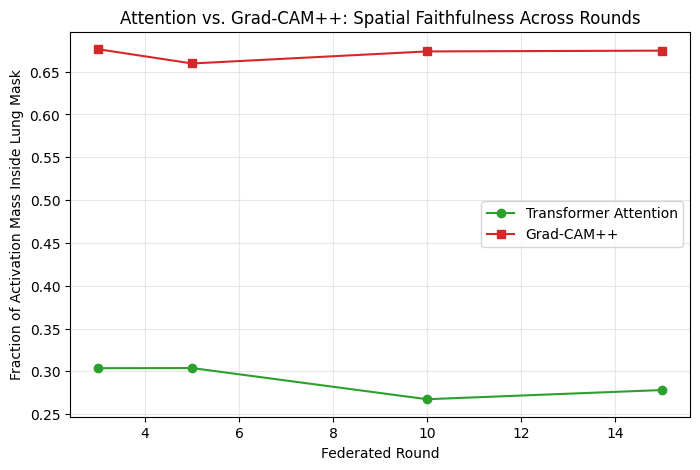

In [ ]:
rounds_common = sorted(xai_results.keys())
plt.figure(figsize=(8,5))
plt.plot(rounds_common, [xai_results[r] for r in rounds_common], marker='o', label='Transformer Attention', color='#2ca02c')
plt.plot(rounds_common, [gradcam_results[r] for r in rounds_common], marker='s', label='Grad-CAM++', color='#d62728')
plt.xlabel("Federated Round")
plt.ylabel("Fraction of Activation Mass Inside Lung Mask")
plt.title("Attention vs. Grad-CAM++: Spatial Faithfulness Across Rounds")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/xai_complementarity_quantitative.png", dpi=300, bbox_inches='tight')
plt.show()

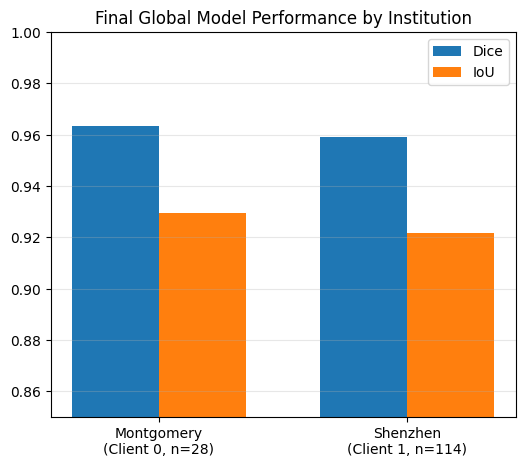

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
MODEL.load_state_dict(torch.load(f"/content/drive/My Drive/FedLungProject/global_model_round_{final_round}.pth", map_location=DEVICE))
mc_dice, mc_iou = evaluate_full(MODEL, client0_val_loader, DEVICE)
sz_dice, sz_iou = evaluate_full(MODEL, client1_val_loader, DEVICE)

labels = ['Montgomery\n(Client 0, n=28)', 'Shenzhen\n(Client 1, n=114)']
dice_vals = [mc_dice, sz_dice]
iou_vals = [mc_iou, sz_iou]

x = np.arange(2); width = 0.35
fig, ax = plt.subplots(figsize=(6,5))
ax.bar(x - width/2, dice_vals, width, label='Dice', color='#1f77b4')
ax.bar(x + width/2, iou_vals, width, label='IoU', color='#ff7f0e')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0.85, 1.0)
ax.set_title("Final Global Model Performance by Institution")
ax.legend(); ax.grid(axis='y', alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/per_client_breakdown.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
ablation_dice_by_round = {}
for r in range(1, 16):
    ckpt = f"/content/drive/My Drive/FedLungProject/ablation_noViT_round_{r}.pth"
    if os.path.exists(ckpt):
        ABLATION_MODEL.load_state_dict(torch.load(ckpt, map_location=DEVICE))
        d, _ = evaluate_full(ABLATION_MODEL, pooled_val_loader, DEVICE)
        ablation_dice_by_round[r] = d

plt.figure(figsize=(8,5))
plt.plot(rounds_sorted, dice_vals, marker='o', label='TransUNetMini (with ViT)', color='#1f77b4')
ar = sorted(ablation_dice_by_round.keys())
plt.plot(ar, [ablation_dice_by_round[r] for r in ar], marker='s', label='ResNet34-UNet (no ViT)', color='#9467bd')
plt.xlabel("Federated Round"); plt.ylabel("Dice")
plt.title("Convergence: With vs Without Transformer Bottleneck")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/ablation_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'ABLATION_MODEL' is not defined

In [ ]:
central_epochs = [e for e,_,_ in central_history]
central_dices = [d for _,d,_ in central_history]

plt.figure(figsize=(8,5))
plt.plot(rounds_sorted, dice_vals, marker='o', label='Federated (per round)', color='#1f77b4')
plt.plot(central_epochs, central_dices, marker='^', label='Centralized (per epoch)', color='#2ca02c')
plt.xlabel("Round / Epoch")
plt.ylabel("Dice")
plt.title("Federated vs Centralized Convergence")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/fed_vs_central_convergence.png", dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
@torch.no_grad()
def per_sample_dice(model, loader, device):
    model.eval()
    dices = []
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        outputs = model(images)
        preds = (torch.sigmoid(outputs) > 0.5).float()
        for i in range(images.size(0)):
            inter = (preds[i] * masks[i]).sum()
            d = (2*inter / (preds[i].sum() + masks[i].sum() + 1e-8)).item()
            dices.append(d)
    return dices

MODEL.load_state_dict(torch.load(f"/content/drive/My Drive/FedLungProject/global_model_round_{final_round}.pth", map_location=DEVICE))
fed_persample = per_sample_dice(MODEL, pooled_val_loader, DEVICE)

plt.figure(figsize=(5,6))
plt.boxplot(fed_persample, vert=True, patch_artist=True, boxprops=dict(facecolor='#1f77b4', alpha=0.6))
plt.scatter(np.random.normal(1, 0.03, len(fed_persample)), fed_persample, alpha=0.4, s=15, color='black')
plt.ylabel("Per-Sample Dice")
plt.title(f"Distribution of Validation Dice Scores (n={len(fed_persample)})")
plt.xticks([1], ['Federated Model, Round 15'])
plt.grid(axis='y', alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/dice_distribution_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"Min: {min(fed_persample):.4f}, Max: {max(fed_persample):.4f}, Median: {np.median(fed_persample):.4f}")

In [ ]:
# ============================================================
# Grad-CAM++ on dec_conv4 (final decoder block) — kept SEPARATE from dec_conv2 results
# ============================================================

gradcam_activations_v2 = {}
gradcam_gradients_v2 = {}

def _save_activation_v2(module, input, output):
    gradcam_activations_v2['value'] = output

def _save_gradient_v2(module, grad_input, grad_output):
    gradcam_gradients_v2['value'] = grad_output[0]

# Hook dec_conv4 instead of dec_conv2 this time
h1_v2 = MODEL.dec_conv4.register_forward_hook(_save_activation_v2)
h2_v2 = MODEL.dec_conv4.register_full_backward_hook(_save_gradient_v2)

def gradcam_mass_in_mask_v2(model, val_loader, device):
    model.eval()
    scores = []
    for images, masks in val_loader:
        for i in range(images.size(0)):
            single_img = images[i:i+1].to(device).requires_grad_(True)
            gt_mask = masks[i, 0].cpu().numpy()

            output = model(single_img)
            model.zero_grad()
            output.sum().backward()

            acts = gradcam_activations_v2['value'][0].detach().cpu().numpy()
            grads = gradcam_gradients_v2['value'][0].detach().cpu().numpy()
            weights = grads.mean(axis=(1, 2))
            cam = np.maximum((weights[:, None, None] * acts).sum(axis=0), 0)

            cam = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_CUBIC)
            cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

            inside = (cam * gt_mask).sum()
            total = cam.sum() + 1e-8
            scores.append(inside / total)
    return float(np.mean(scores))

# Saved as a NEW dict — gradcam_results (dec_conv2) from before stays untouched
gradcam_results_dec4 = {}
for r in [3, 5, 10, 15]:
    weight_file = f"/content/drive/My Drive/FedLungProject/global_model_round_{r}.pth"
    MODEL.load_state_dict(torch.load(weight_file, map_location=DEVICE))
    score = gradcam_mass_in_mask_v2(MODEL, pooled_val_loader, DEVICE)
    gradcam_results_dec4[r] = score
    print(f"Round {r}: Grad-CAM++ (dec_conv4) mass inside mask = {score:.4f}")

h1_v2.remove(); h2_v2.remove()

In [ ]:
rounds_common = sorted(gradcam_results.keys())  # from your original dec_conv2 run

plt.figure(figsize=(8,5))
plt.plot(rounds_common, [gradcam_results[r] for r in rounds_common], marker='o', label='Grad-CAM++ (dec_conv2, 28×28)', color='#d62728')
plt.plot(rounds_common, [gradcam_results_dec4[r] for r in rounds_common], marker='s', label='Grad-CAM++ (dec_conv4, 112×112)', color='#8c564b')
plt.xlabel("Federated Round")
plt.ylabel("Fraction of Activation Mass Inside Lung Mask")
plt.title("Grad-CAM++ Layer Comparison: dec_conv2 vs dec_conv4")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/content/drive/My Drive/FedLungProject/gradcam_layer_comparison.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"\nMean mass-in-mask, dec_conv2: {np.mean(list(gradcam_results.values())):.4f}")
print(f"Mean mass-in-mask, dec_conv4: {np.mean(list(gradcam_results_dec4.values())):.4f}")

In [ ]:
def get_cam_for_layer(model, layer, single_img):
    acts_dict, grads_dict = {}, {}
    def fwd(m, i, o): acts_dict['v'] = o
    def bwd(m, gi, go): grads_dict['v'] = go[0]
    h1 = layer.register_forward_hook(fwd)
    h2 = layer.register_full_backward_hook(bwd)

    single_img = single_img.clone().requires_grad_(True)
    output = model(single_img)
    model.zero_grad()
    output.sum().backward()

    acts = acts_dict['v'][0].detach().cpu().numpy()
    grads = grads_dict['v'][0].detach().cpu().numpy()
    weights = grads.mean(axis=(1,2))
    cam = np.maximum((weights[:,None,None]*acts).sum(axis=0), 0)
    cam = cv2.resize(cam, (224,224), interpolation=cv2.INTER_CUBIC)
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    h1.remove(); h2.remove()
    return cam

MODEL.load_state_dict(torch.load("/content/drive/My Drive/FedLungProject/global_model_round_15.pth", map_location=DEVICE))
images, masks = next(iter(client0_val_loader))
single_img = images[0:1].to(DEVICE)

cam_dec2 = get_cam_for_layer(MODEL, MODEL.dec_conv2, single_img)
cam_dec4 = get_cam_for_layer(MODEL, MODEL.dec_conv4, single_img)

src_img = single_img[0].detach().permute(1,2,0).cpu().numpy()
src_img = (src_img * np.array([0.229,0.224,0.225])) + np.array([0.485,0.456,0.406])
src_img = np.clip(src_img, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(14,5))
ax[0].imshow(src_img); ax[0].set_title("Input"); ax[0].axis('off')
ax[1].imshow(src_img); ax[1].imshow(cam_dec2, cmap='jet', alpha=0.45); ax[1].set_title("Grad-CAM++ (dec_conv2)"); ax[1].axis('off')
ax[2].imshow(src_img); ax[2].imshow(cam_dec4, cmap='jet', alpha=0.45); ax[2].set_title("Grad-CAM++ (dec_conv4)"); ax[2].axis('off')
plt.savefig("/content/drive/My Drive/FedLungProject/gradcam_layer_qualitative_comparison.png", dpi=300, bbox_inches='tight')
plt.show()